calculate brunt_visala freq v2

In [1]:
import numpy as np                   
import xarray as xr  
import matplotlib.pyplot as plt   
import gsw

In [2]:
pt=xr.open_dataarray(r"D:\data\observation\other\soda_monthly2018_2022\soda_1980_2022_potential_temp2.nc")
sa=xr.open_dataarray(r"D:\data\observation\other\soda_monthly2018_2022\soda_1980_2022_practical_salt1.nc")

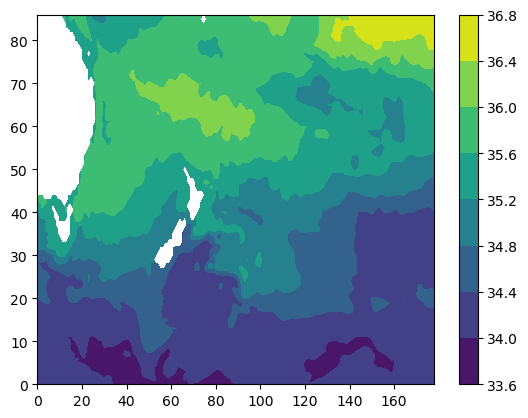

In [3]:
abs_salinity=gsw.conversions.SA_from_SP(sa, sa.st_ocean, sa.xt_ocean, sa.yt_ocean) 
plt.contourf(abs_salinity[0,5,:,:])
plt.colorbar()
conversion_temp=gsw.conversions.CT_from_pt(abs_salinity, pt)
sigma0=gsw.density.sigma0(abs_salinity, conversion_temp)+1000
#N_square=9.81*(sigma0[:,16,:,:]-sigma0[:,0,:,:])/(np.nanmean(sigma0.loc[:,0:35,:,:],axis=1)*(2.012630e+02-5.033550e+00))

In [4]:
np.sum((conversion_temp[:,0,:,:]-conversion_temp[:,35,:,:])<0)

<xarray.DataArray 'salt' ()>
array(143406)

发现一个问题，g随着维度的变化对于浮力频率的变化影响是大的 因此需要写一个重力加速度场g随着纬度变化的函数
g = 9.780327 * (1 + 0.0053024 * sin^2(纬度) - 0.0000058 * sin^2(2 * 纬度))

In [5]:
import math

In [6]:
def cal_g(latitude):
    g=9.780327*(1+0.0053024*((math.sin(latitude*math.pi/180))**2)-0.0000058*((math.sin(2*latitude*math.pi/180))**2))
    return g 

In [7]:
np.sum((sigma0[:,16,:,:]-sigma0[:,0,:,:])<0)

<xarray.DataArray 'salt' ()>
array(65672)

In [8]:
lat=sa.yt_ocean

In [9]:
g=np.zeros((87))
for i in range(0,87):
    g[i]=cal_g(lat[i])

In [10]:
g=np.tile(g,(179,1))

In [11]:
g=np.tile(g,(516,1,1))

In [12]:
g=np.swapaxes(g,1,2)

In [13]:
sigma0

<xarray.DataArray 'salt' (time: 516, st_ocean: 50, yt_ocean: 87, xt_ocean: 179)>
array([[[[1026.83675847, 1026.8513588 , 1026.86319256, ...,
          1026.74751098, 1026.73753329, 1026.73371307],
         [1026.73301545, 1026.76264785, 1026.80564413, ...,
          1026.76823901, 1026.76316136, 1026.76100069],
         [1026.71156206, 1026.76194238, 1026.81226499, ...,
          1026.8041498 , 1026.80977397, 1026.80947001],
         ...,
         [          nan,           nan,           nan, ...,
          1023.53277275, 1023.54158569, 1023.56031733],
         [1019.90585408,           nan,           nan, ...,
          1023.51211284, 1023.51948912, 1023.53916   ],
         [1020.61147934,           nan,           nan, ...,
          1023.50257212, 1023.51155738, 1023.52531181]],

        [[1026.84446625, 1026.85808596, 1026.87162097, ...,
          1026.75573622, 1026.74603647, 1026.74326383],
         [1026.73951872, 1026.77111216, 1026.81639088, ...,
          1026.77721068, 1026.77137966, 1026.7685349 ],
         [1026.72238444, 1026.77446503, 1026.83051703, ...,
          1026.81499918, 1026.82129335, 1026.82084678],
...
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan]],

        [[          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         ...,
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan],
         [          nan,           nan,           nan, ...,
                    nan,           nan,           nan]]]])
Coordinates:
  * time      (time) datetime64[ns] 1980-01-16T01:00:00 ... 2022-12-13T13:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
  * st_ocean  (st_ocean) float64 5.034 15.1 25.22 ... 5.185e+03 5.395e+03

In [14]:
sigma0[:,0:5,:,:]

<xarray.DataArray 'salt' (time: 516, st_ocean: 5, yt_ocean: 87, xt_ocean: 179)>
array([[[[1026.83675847, 1026.8513588 , 1026.86319256, ...,
          1026.74751098, 1026.73753329, 1026.73371307],
         [1026.73301545, 1026.76264785, 1026.80564413, ...,
          1026.76823901, 1026.76316136, 1026.76100069],
         [1026.71156206, 1026.76194238, 1026.81226499, ...,
          1026.8041498 , 1026.80977397, 1026.80947001],
         ...,
         [          nan,           nan,           nan, ...,
          1023.53277275, 1023.54158569, 1023.56031733],
         [1019.90585408,           nan,           nan, ...,
          1023.51211284, 1023.51948912, 1023.53916   ],
         [1020.61147934,           nan,           nan, ...,
          1023.50257212, 1023.51155738, 1023.52531181]],

        [[1026.84446625, 1026.85808596, 1026.87162097, ...,
          1026.75573622, 1026.74603647, 1026.74326383],
         [1026.73951872, 1026.77111216, 1026.81639088, ...,
          1026.77721068, 1026.77137966, 1026.7685349 ],
         [1026.72238444, 1026.77446503, 1026.83051703, ...,
          1026.81499918, 1026.82129335, 1026.82084678],
...
         [          nan,           nan,           nan, ...,
          1024.09217   , 1024.01744429, 1023.9571838 ],
         [1022.70323461,           nan,           nan, ...,
          1023.98360743, 1023.96736857, 1023.90432918],
         [1022.5238109 ,           nan,           nan, ...,
          1023.82823542, 1023.86631501, 1023.89337447]],

        [[1027.11982198, 1027.10777858, 1027.12775023, ...,
          1027.15447544, 1027.12474674, 1027.16275782],
         [1027.04472224, 1027.0796795 , 1027.13073232, ...,
          1027.20747774, 1027.20054502, 1027.20336402],
         [1027.02343331, 1027.04805261, 1027.1056765 , ...,
          1027.22298561, 1027.23028842, 1027.22454957],
         ...,
         [          nan,           nan,           nan, ...,
          1024.30355539, 1024.24052858, 1024.15687219],
         [          nan,           nan,           nan, ...,
          1024.22947889, 1024.2107552 , 1024.13096345],
         [          nan,           nan,           nan, ...,
          1024.06663843, 1024.09317813, 1024.09685836]]]])
Coordinates:
  * time      (time) datetime64[ns] 1980-01-16T01:00:00 ... 2022-12-13T13:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
  * st_ocean  (st_ocean) float64 5.034 15.1 25.22 35.36 45.58

自己计算BV freq

In [15]:
N_square=g*(sigma0[:,4,:,:]-sigma0[:,0,:,:])/(np.nanmean(sigma0[:,0:5,:,:],axis=1)*(45.576351-5.033550e+00))

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_24660\596154232.py:1: RuntimeWarning: Mean of empty slice
  N_square=g*(sigma0[:,4,:,:]-sigma0[:,0,:,:])/(np.nanmean(sigma0[:,0:5,:,:],axis=1)*(45.576351-5.033550e+00))


In [16]:
np.sum(np.isnan(N_square))

<xarray.DataArray 'salt' ()>
array(513936)

In [17]:
513936/(516*87*179)

0.06395684839144673

In [18]:
N_square.shape

(516, 87, 179)

In [19]:
np.sum(N_square<0) # 0.8%＜0的值

<xarray.DataArray 'salt' ()>
array(270767)

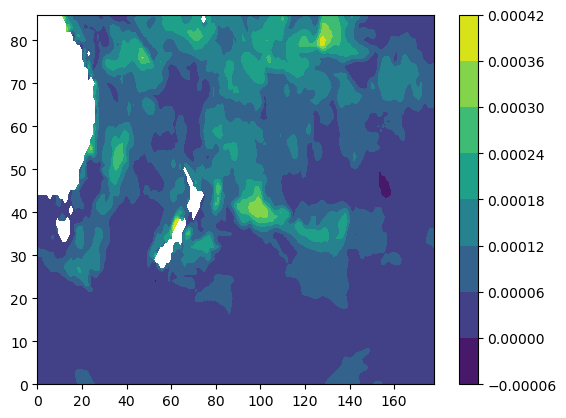

In [20]:
plt.contourf(N_square[0,:,:])
plt.colorbar()

In [21]:
N_square_monthly=N_square.groupby('time.month').mean(dim='time')
N_square_seasonaly=N_square[2:,:,:].groupby('time.season').mean()

计算anomaly

In [22]:
N_square_anom=N_square.groupby('time.month')-N_square_monthly

In [23]:
N_square_anom

<xarray.DataArray 'salt' (time: 516, yt_ocean: 87, xt_ocean: 179)>
array([[[-1.32161984e-05, -1.31809204e-05, -1.41387103e-05, ...,
         -1.88353762e-05, -1.67432728e-05, -1.40465894e-05],
        [ 1.91486951e-05,  1.36638909e-05,  4.55095058e-06, ...,
         -1.15558653e-05, -1.40894323e-05, -1.57818662e-05],
        [ 2.92934830e-05,  1.73612608e-05,  5.99037086e-06, ...,
         -1.27598402e-05, -1.31629805e-05, -1.26103427e-05],
        ...,
        [            nan,             nan,             nan, ...,
         -4.95225673e-05, -4.72372191e-05, -4.34341315e-05],
        [            nan,             nan,             nan, ...,
         -4.62673143e-05, -4.51378008e-05, -4.33396213e-05],
        [            nan,             nan,             nan, ...,
         -4.60323085e-05, -4.45046115e-05, -4.25564721e-05]],

       [[ 3.22202351e-05,  3.61648324e-05,  3.79982401e-05, ...,
         -1.85542825e-05, -1.88082171e-05, -1.79446492e-05],
        [ 3.20964088e-05,  3.55083451e-05,  3.96195463e-05, ...,
         -1.61350835e-05, -1.79248208e-05, -1.79876744e-05],
        [ 3.05151931e-05,  4.00166507e-05,  4.80836657e-05, ...,
         -1.56328456e-05, -1.59373884e-05, -1.76702217e-05],
...
        [            nan,             nan,             nan, ...,
          3.60860770e-05,  3.47342427e-05,  2.43054663e-05],
        [            nan,             nan,             nan, ...,
          4.92555046e-05,  5.24769783e-05,  3.33755215e-05],
        [            nan,             nan,             nan, ...,
          4.44307210e-05,  2.78118872e-05,  1.61415718e-05]],

       [[-4.37380733e-05, -4.15682090e-05, -4.11838284e-05, ...,
          2.15257641e-05,  1.68383074e-05,  2.57179411e-05],
        [-2.97532916e-05, -2.76720232e-05, -2.78169305e-05, ...,
          5.42749637e-05,  5.81259754e-05,  5.96532613e-05],
        [-2.01443396e-05, -2.02753848e-05, -1.91780209e-05, ...,
          7.40192028e-05,  7.35810683e-05,  7.80526928e-05],
        ...,
        [            nan,             nan,             nan, ...,
          5.84112402e-05,  4.33066582e-05,  1.74881727e-05],
        [            nan,             nan,             nan, ...,
          6.16055391e-05,  4.38770493e-05,  1.34620833e-05],
        [            nan,             nan,             nan, ...,
          2.10306104e-05,  1.45432570e-05,  5.87375785e-06]]])
Coordinates:
  * time      (time) datetime64[ns] 1980-01-16T01:00:00 ... 2022-12-13T13:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     (time) int64 1 2 3 4 5 6 7 8 9 10 11 ... 2 3 4 5 6 7 8 9 10 11 12

In [24]:
N_square_anom_84=N_square_anom.loc['1984-12':'1985-2',:,:]
N_square_anom_85=N_square_anom.loc['1985-12':'1986-2',:,:]
N_square_anom_86=N_square_anom.loc['1986-12':'1987-2',:,:]
N_square_anom_01=N_square_anom.loc['2001-12':'2002-2',:,:]
N_square_anom_17=N_square_anom.loc['2017-12':'2018-2',:,:]
N_square_anom_18=N_square_anom.loc['2018-12':'2019-2',:,:]
N_square_anom_21=N_square_anom.loc['2021-12':'2022-2',:,:]
N_square_anom_22=N_square_anom.loc['2022-12',:,:]

In [25]:
N_square_anom_compose=xr.concat((N_square_anom_84,N_square_anom_85,N_square_anom_86,N_square_anom_01,N_square_anom_17,N_square_anom_18,N_square_anom_21,N_square_anom_22),dim='time')

In [26]:
N_square_anom_compose

<xarray.DataArray 'salt' (time: 22, yt_ocean: 87, xt_ocean: 179)>
array([[[ 1.35821783e-05,  1.22439635e-05,  7.92601682e-06, ...,
          2.35197640e-06, -7.89807537e-07, -3.25344181e-07],
        [ 2.08697671e-05,  1.93094515e-05,  2.05228849e-05, ...,
         -2.14610996e-06, -3.58278373e-06, -6.01136690e-06],
        [ 2.48187334e-05,  2.03739804e-05,  2.19164336e-05, ...,
         -1.17760872e-05, -1.13685086e-05, -1.09906917e-05],
        ...,
        [            nan,             nan,             nan, ...,
          5.11450339e-06,  4.40192113e-06, -4.11287573e-06],
        [            nan,             nan,             nan, ...,
          4.27120072e-06, -3.62607585e-06, -1.41383705e-05],
        [            nan,             nan,             nan, ...,
         -6.16958731e-06, -1.27536301e-05, -1.42105361e-05]],

       [[ 5.90454684e-05,  5.40990867e-05,  5.93023015e-05, ...,
          5.89615931e-06,  1.20011620e-05,  1.35556381e-05],
        [ 7.40094425e-05,  6.22416490e-05,  6.43250572e-05, ...,
         -1.14768255e-06,  3.17575234e-06,  7.34552589e-06],
        [ 6.91468453e-05,  6.72803880e-05,  6.20803590e-05, ...,
         -3.27229919e-06, -2.81916990e-06, -1.62695521e-06],
...
        [            nan,             nan,             nan, ...,
          1.89311479e-06, -2.58500597e-06,  1.94212614e-07],
        [            nan,             nan,             nan, ...,
         -1.04925913e-05, -6.55504768e-06, -1.40692985e-06],
        [            nan,             nan,             nan, ...,
         -2.23323733e-05, -1.80871786e-05, -1.05775793e-05]],

       [[-4.37380733e-05, -4.15682090e-05, -4.11838284e-05, ...,
          2.15257641e-05,  1.68383074e-05,  2.57179411e-05],
        [-2.97532916e-05, -2.76720232e-05, -2.78169305e-05, ...,
          5.42749637e-05,  5.81259754e-05,  5.96532613e-05],
        [-2.01443396e-05, -2.02753848e-05, -1.91780209e-05, ...,
          7.40192028e-05,  7.35810683e-05,  7.80526928e-05],
        ...,
        [            nan,             nan,             nan, ...,
          5.84112402e-05,  4.33066582e-05,  1.74881727e-05],
        [            nan,             nan,             nan, ...,
          6.16055391e-05,  4.38770493e-05,  1.34620833e-05],
        [            nan,             nan,             nan, ...,
          2.10306104e-05,  1.45432570e-05,  5.87375785e-06]]])
Coordinates:
  * time      (time) datetime64[ns] 1984-12-15T01:00:00 ... 2022-12-13T13:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     (time) int64 12 1 2 12 1 2 12 1 2 12 1 2 12 1 2 12 1 2 12 1 2 12

In [27]:
N_square_anom

<xarray.DataArray 'salt' (time: 516, yt_ocean: 87, xt_ocean: 179)>
array([[[-1.32161984e-05, -1.31809204e-05, -1.41387103e-05, ...,
         -1.88353762e-05, -1.67432728e-05, -1.40465894e-05],
        [ 1.91486951e-05,  1.36638909e-05,  4.55095058e-06, ...,
         -1.15558653e-05, -1.40894323e-05, -1.57818662e-05],
        [ 2.92934830e-05,  1.73612608e-05,  5.99037086e-06, ...,
         -1.27598402e-05, -1.31629805e-05, -1.26103427e-05],
        ...,
        [            nan,             nan,             nan, ...,
         -4.95225673e-05, -4.72372191e-05, -4.34341315e-05],
        [            nan,             nan,             nan, ...,
         -4.62673143e-05, -4.51378008e-05, -4.33396213e-05],
        [            nan,             nan,             nan, ...,
         -4.60323085e-05, -4.45046115e-05, -4.25564721e-05]],

       [[ 3.22202351e-05,  3.61648324e-05,  3.79982401e-05, ...,
         -1.85542825e-05, -1.88082171e-05, -1.79446492e-05],
        [ 3.20964088e-05,  3.55083451e-05,  3.96195463e-05, ...,
         -1.61350835e-05, -1.79248208e-05, -1.79876744e-05],
        [ 3.05151931e-05,  4.00166507e-05,  4.80836657e-05, ...,
         -1.56328456e-05, -1.59373884e-05, -1.76702217e-05],
...
        [            nan,             nan,             nan, ...,
          3.60860770e-05,  3.47342427e-05,  2.43054663e-05],
        [            nan,             nan,             nan, ...,
          4.92555046e-05,  5.24769783e-05,  3.33755215e-05],
        [            nan,             nan,             nan, ...,
          4.44307210e-05,  2.78118872e-05,  1.61415718e-05]],

       [[-4.37380733e-05, -4.15682090e-05, -4.11838284e-05, ...,
          2.15257641e-05,  1.68383074e-05,  2.57179411e-05],
        [-2.97532916e-05, -2.76720232e-05, -2.78169305e-05, ...,
          5.42749637e-05,  5.81259754e-05,  5.96532613e-05],
        [-2.01443396e-05, -2.02753848e-05, -1.91780209e-05, ...,
          7.40192028e-05,  7.35810683e-05,  7.80526928e-05],
        ...,
        [            nan,             nan,             nan, ...,
          5.84112402e-05,  4.33066582e-05,  1.74881727e-05],
        [            nan,             nan,             nan, ...,
          6.16055391e-05,  4.38770493e-05,  1.34620833e-05],
        [            nan,             nan,             nan, ...,
          2.10306104e-05,  1.45432570e-05,  5.87375785e-06]]])
Coordinates:
  * time      (time) datetime64[ns] 1980-01-16T01:00:00 ... 2022-12-13T13:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     (time) int64 1 2 3 4 5 6 7 8 9 10 11 ... 2 3 4 5 6 7 8 9 10 11 12

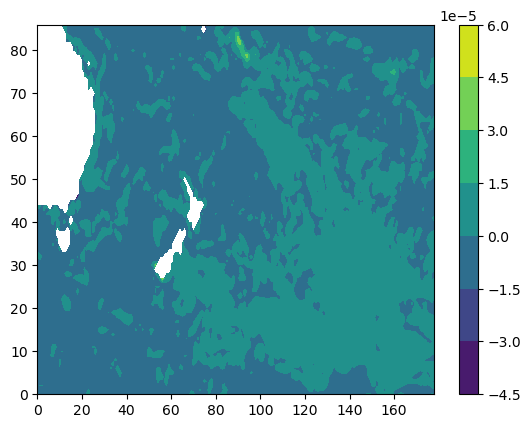

In [28]:
plt.contourf(N_square_anom[450,:,:])
plt.colorbar()

In [29]:
N_square_anom_compose_monthly_mean=N_square_anom_compose.groupby('time.month').mean()

In [30]:
N_square_anom_compose[:21,:,:]

<xarray.DataArray 'salt' (time: 21, yt_ocean: 87, xt_ocean: 179)>
array([[[ 1.35821783e-05,  1.22439635e-05,  7.92601682e-06, ...,
          2.35197640e-06, -7.89807537e-07, -3.25344181e-07],
        [ 2.08697671e-05,  1.93094515e-05,  2.05228849e-05, ...,
         -2.14610996e-06, -3.58278373e-06, -6.01136690e-06],
        [ 2.48187334e-05,  2.03739804e-05,  2.19164336e-05, ...,
         -1.17760872e-05, -1.13685086e-05, -1.09906917e-05],
        ...,
        [            nan,             nan,             nan, ...,
          5.11450339e-06,  4.40192113e-06, -4.11287573e-06],
        [            nan,             nan,             nan, ...,
          4.27120072e-06, -3.62607585e-06, -1.41383705e-05],
        [            nan,             nan,             nan, ...,
         -6.16958731e-06, -1.27536301e-05, -1.42105361e-05]],

       [[ 5.90454684e-05,  5.40990867e-05,  5.93023015e-05, ...,
          5.89615931e-06,  1.20011620e-05,  1.35556381e-05],
        [ 7.40094425e-05,  6.22416490e-05,  6.43250572e-05, ...,
         -1.14768255e-06,  3.17575234e-06,  7.34552589e-06],
        [ 6.91468453e-05,  6.72803880e-05,  6.20803590e-05, ...,
         -3.27229919e-06, -2.81916990e-06, -1.62695521e-06],
...
        [            nan,             nan,             nan, ...,
         -1.22839023e-05, -8.29600106e-06,  3.89274105e-06],
        [            nan,             nan,             nan, ...,
         -1.97214978e-06, -1.78414771e-05, -1.29422566e-05],
        [            nan,             nan,             nan, ...,
          1.12203459e-06, -2.06011870e-05, -3.02234403e-05]],

       [[-3.90996831e-05, -3.63448960e-05, -3.47576935e-05, ...,
         -2.86953779e-05, -2.85135469e-05, -2.57817504e-05],
        [-2.98469933e-05, -3.01235616e-05, -3.09746996e-05, ...,
         -3.21864297e-05, -3.19762704e-05, -3.07290044e-05],
        [-2.20689569e-05, -2.32151753e-05, -2.52834530e-05, ...,
         -3.18624617e-05, -3.19520487e-05, -3.24898775e-05],
        ...,
        [            nan,             nan,             nan, ...,
          1.89311479e-06, -2.58500597e-06,  1.94212614e-07],
        [            nan,             nan,             nan, ...,
         -1.04925913e-05, -6.55504768e-06, -1.40692985e-06],
        [            nan,             nan,             nan, ...,
         -2.23323733e-05, -1.80871786e-05, -1.05775793e-05]]])
Coordinates:
  * time      (time) datetime64[ns] 1984-12-15T01:00:00 ... 2022-02-14T01:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     (time) int64 12 1 2 12 1 2 12 1 2 12 1 2 12 1 2 12 1 2 12 1 2

In [31]:
a=np.array(N_square_anom_compose[:21,:,:].groupby('time.season'))

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_24660\2604813228.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  a=np.array(N_square_anom_compose[:21,:,:].groupby('time.season'))


Text(0.5, 1.0, '1981-2023 DJF')

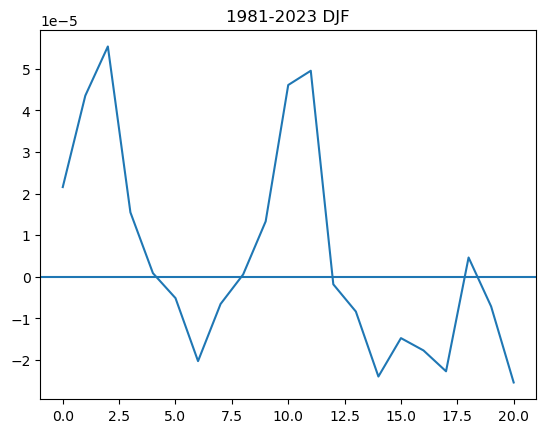

In [32]:
plt.plot(a[0,1].mean(axis=(1,2)))
plt.axhline(0)
plt.title('1981-2023 DJF')

In [33]:
b=np.array(N_square_anom_compose.groupby('time.month'))

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_24660\420227549.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  b=np.array(N_square_anom_compose.groupby('time.month'))


Text(0.5, 1.0, '1981-2023 Jan')

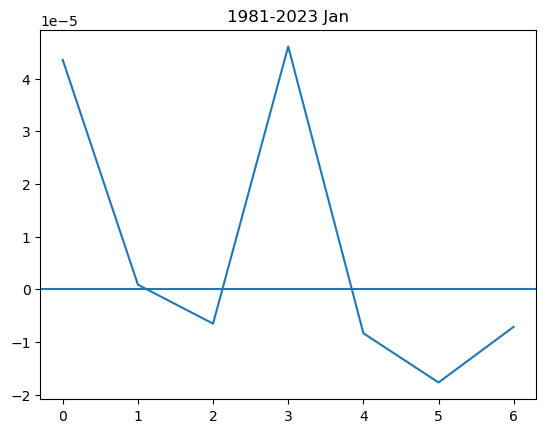

In [34]:
plt.plot(b[0,1].mean(axis=(1,2)))
plt.axhline(0)
plt.title('1981-2023 Jan')

T检验

In [35]:
from scipy.stats.mstats import ttest_ind


In [36]:
N_square

<xarray.DataArray 'salt' (time: 516, yt_ocean: 87, xt_ocean: 179)>
array([[[3.78062538e-05, 3.59002360e-05, 3.49344604e-05, ...,
         1.54385742e-05, 1.66231575e-05, 1.84476205e-05],
        [5.72427269e-05, 5.16403492e-05, 4.31112816e-05, ...,
         2.16043435e-05, 1.97775882e-05, 1.85821315e-05],
        [5.86253414e-05, 4.71009750e-05, 3.72730932e-05, ...,
         2.08603071e-05, 2.08240985e-05, 2.09324180e-05],
        ...,
        [           nan,            nan,            nan, ...,
         4.63265919e-06, 7.54502398e-06, 7.57248329e-06],
        [           nan,            nan,            nan, ...,
         2.17404847e-06, 2.65380376e-06, 2.24783820e-06],
        [           nan,            nan,            nan, ...,
         1.41689080e-06, 1.35072047e-06, 1.23396634e-06]],

       [[7.34952623e-05, 7.52864335e-05, 7.61704437e-05, ...,
         1.28077270e-05, 1.25153516e-05, 1.31771616e-05],
        [6.32610662e-05, 6.69867405e-05, 7.19450163e-05, ...,
         1.67003169e-05, 1.55156534e-05, 1.50513796e-05],
        [5.42646972e-05, 6.48782717e-05, 7.50093236e-05, ...,
         1.73346292e-05, 1.72505043e-05, 1.61176278e-05],
...
        [           nan,            nan,            nan, ...,
         9.37402460e-05, 9.01133218e-05, 7.84511221e-05],
        [           nan,            nan,            nan, ...,
         1.00363261e-04, 1.02432673e-04, 8.39617414e-05],
        [           nan,            nan,            nan, ...,
         8.81258757e-05, 7.12225671e-05, 6.09392490e-05]],

       [[3.15290058e-07, 5.85298182e-07, 9.61783077e-07, ...,
         4.59790699e-05, 4.14334764e-05, 5.06232959e-05],
        [6.85020581e-07, 2.19889782e-06, 2.54778768e-06, ...,
         7.95463090e-05, 8.45108402e-05, 8.74733581e-05],
        [1.41685582e-06, 1.93978608e-06, 3.50352458e-06, ...,
         1.00089031e-04, 1.00217102e-04, 1.04700829e-04],
        ...,
        [           nan,            nan,            nan, ...,
         1.18686115e-04, 1.06003040e-04, 7.95016660e-05],
        [           nan,            nan,            nan, ...,
         1.19230726e-04, 1.04333802e-04, 7.34942941e-05],
        [           nan,            nan,            nan, ...,
         7.59323019e-05, 7.15454055e-05, 6.20109008e-05]]])
Coordinates:
  * time      (time) datetime64[ns] 1980-01-16T01:00:00 ... 2022-12-13T13:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25

In [37]:
N_square_84=N_square.loc['1984-12':'1985-2',:,:]
N_square_85=N_square.loc['1985-12':'1986-2',:,:]
N_square_86=N_square.loc['1986-12':'1987-2',:,:]
N_square_01=N_square.loc['2001-12':'2002-2',:,:]
N_square_17=N_square.loc['2017-12':'2018-2',:,:]
N_square_18=N_square.loc['2018-12':'2019-2',:,:]
N_square_21=N_square.loc['2021-12':'2022-2',:,:]
N_square_compose=xr.concat((N_square_84,N_square_85,N_square_86,N_square_01,N_square_17,N_square_18,N_square_21),dim='time')

In [38]:
N_square_compose_month=N_square_compose.groupby('time.month')

In [39]:
N_square_compose_season=N_square_compose.groupby('time.season')

In [40]:
N_square_compose_month[1]

<xarray.DataArray 'salt' (time: 7, yt_ocean: 87, xt_ocean: 179)>
array([[[1.10067921e-04, 1.03180243e-04, 1.08375472e-04, ...,
         4.01701097e-05, 4.53675923e-05, 4.60498479e-05],
        [1.12103474e-04, 1.00218107e-04, 1.02885388e-04, ...,
         3.20125263e-05, 3.70427729e-05, 4.17095236e-05],
        [9.84787038e-05, 9.70201021e-05, 9.33630813e-05, ...,
         3.03478482e-05, 3.11679091e-05, 3.19158055e-05],
        ...,
        [           nan,            nan,            nan, ...,
         3.67021274e-05, 2.78612396e-05, 2.95781626e-05],
        [           nan,            nan,            nan, ...,
         3.39180364e-05, 2.11579231e-05, 1.26866068e-05],
        [           nan,            nan,            nan, ...,
         1.14420197e-05, 4.54537938e-06, 4.17803165e-06]],

       [[3.02444737e-06, 3.29563532e-06, 4.96471821e-06, ...,
         2.21073114e-05, 1.85644703e-05, 1.68995995e-05],
        [2.83735340e-06, 1.80787116e-06, 1.72594626e-06, ...,
         2.31296459e-05, 1.82260550e-05, 1.50545762e-05],
        [8.44804525e-06, 4.90761675e-06, 2.12457981e-06, ...,
         2.01248971e-05, 1.62754792e-05, 1.17051559e-05],
...
        [           nan,            nan,            nan, ...,
         4.66006885e-05, 4.80542934e-05, 4.92822202e-05],
        [           nan,            nan,            nan, ...,
         1.02666112e-05, 9.79963023e-06, 1.15482001e-05],
        [           nan,            nan,            nan, ...,
         1.21299140e-05, 8.98714463e-06, 1.62840968e-05]],

       [[9.68716877e-06, 9.66173632e-06, 8.47221559e-06, ...,
         6.13465837e-05, 7.11351824e-05, 8.16006097e-05],
        [2.56708282e-06, 2.12597555e-06, 2.08124588e-06, ...,
         1.60875683e-05, 1.85076663e-05, 1.99335554e-05],
        [7.27631992e-06, 7.88743630e-06, 6.25510357e-06, ...,
         2.78862593e-06, 4.65411316e-06, 4.51594257e-06],
        ...,
        [           nan,            nan,            nan, ...,
         4.18713242e-05, 4.64862421e-05, 5.48993558e-05],
        [           nan,            nan,            nan, ...,
         4.64692130e-05, 2.99501275e-05, 3.26452029e-05],
        [           nan,            nan,            nan, ...,
         4.85712339e-05, 2.52541449e-05, 1.35669981e-05]]])
Coordinates:
  * time      (time) datetime64[ns] 1985-01-16T13:00:00 ... 2022-01-15T01:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25

In [41]:
N_square_clim=N_square.groupby('time.month').mean()


In [42]:
N_square_clim[0]

<xarray.DataArray 'salt' (yt_ocean: 87, xt_ocean: 179)>
array([[5.10224522e-05, 4.90811564e-05, 4.90731707e-05, ...,
        3.42739504e-05, 3.33664303e-05, 3.24942098e-05],
       [3.80940319e-05, 3.79764582e-05, 3.85603311e-05, ...,
        3.31602088e-05, 3.38670205e-05, 3.43639977e-05],
       [2.93318585e-05, 2.97397142e-05, 3.12827223e-05, ...,
        3.36201474e-05, 3.39870790e-05, 3.35427607e-05],
       ...,
       [           nan,            nan,            nan, ...,
        5.41552265e-05, 5.47822431e-05, 5.10066148e-05],
       [           nan,            nan,            nan, ...,
        4.84413628e-05, 4.77916046e-05, 4.55874595e-05],
       [           nan,            nan,            nan, ...,
        4.74491993e-05, 4.58553320e-05, 4.37904384e-05]])
Coordinates:
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     int64 1

In [43]:
np.tile(np.array(N_square_clim[2]),(7,1,1)).shape

(7, 87, 179)

In [44]:
N_square_clim[11]

<xarray.DataArray 'salt' (yt_ocean: 87, xt_ocean: 179)>
array([[4.40533633e-05, 4.21535072e-05, 4.21456115e-05, ...,
        2.44533058e-05, 2.45951689e-05, 2.49053548e-05],
       [3.04383121e-05, 2.98709211e-05, 3.03647182e-05, ...,
        2.52713453e-05, 2.63848648e-05, 2.78200968e-05],
       [2.15611954e-05, 2.22151709e-05, 2.26815455e-05, ...,
        2.60698284e-05, 2.66360340e-05, 2.66481363e-05],
       ...,
       [           nan,            nan,            nan, ...,
        6.02748746e-05, 6.26963818e-05, 6.20134932e-05],
       [           nan,            nan,            nan, ...,
        5.76251866e-05, 6.04567531e-05, 6.00322108e-05],
       [           nan,            nan,            nan, ...,
        5.49016914e-05, 5.70021485e-05, 5.61371429e-05]])
Coordinates:
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     int64 12

In [45]:
_,p_N_square12=ttest_ind(N_square_compose_month[12],np.tile(np.array(N_square_clim[11]),(7,1,1)),equal_var=True)

In [46]:
p_N_square12

masked_array(
  data=[[0.2627842090929779, 0.3798209588789071, 0.31414139373830785,
         ..., 0.91499004469264, 0.8744732656746854, 0.8685900357682312],
        [0.858392949844655, 0.8083989295083481, 0.6582332498826846, ...,
         0.2588773901731362, 0.6243614472696687, 0.8419577435453768],
        [0.675136772693224, 0.7848628347177526, 0.889395971449841, ...,
         0.7480549266551302, 0.7286673193023556, 0.7543167041564904],
        ...,
        [--, --, --, ..., 0.655498732250317, 0.6618689845576285,
         0.5408184204024451],
        [--, --, --, ..., 0.7065639564942765, 0.7008728137511826,
         0.5934508614342078],
        [--, --, --, ..., 0.5129847554608647, 0.4155885813019111,
         0.4325100761884225]],
  mask=[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, ..., False, False, False],
        [ True, 

In [47]:
_,p_N_square1=ttest_ind(N_square_compose_month[1],np.tile(np.array(N_square_clim[0]),(7,1,1)),equal_var=True)
_,p_N_square2=ttest_ind(N_square_compose_month[2],np.tile(np.array(N_square_clim[1]),(7,1,1)),equal_var=True)

In [48]:
N_square_compose_season['DJF']

<xarray.DataArray 'salt' (time: 21, yt_ocean: 87, xt_ocean: 179)>
array([[[ 5.76355416e-05,  5.43974707e-05,  5.00716283e-05, ...,
          2.68052822e-05,  2.38053614e-05,  2.45800106e-05],
        [ 5.13080792e-05,  4.91803726e-05,  5.08876031e-05, ...,
          2.31252353e-05,  2.28020811e-05,  2.18087299e-05],
        [ 4.63799288e-05,  4.25891512e-05,  4.45979791e-05, ...,
          1.42937413e-05,  1.52675255e-05,  1.56574445e-05],
        ...,
        [            nan,             nan,             nan, ...,
          6.53893780e-05,  6.70983030e-05,  5.79006175e-05],
        [            nan,             nan,             nan, ...,
          6.18963873e-05,  5.68306773e-05,  4.58938403e-05],
        [            nan,             nan,             nan, ...,
          4.87321041e-05,  4.42485184e-05,  4.19266068e-05]],

       [[ 1.10067921e-04,  1.03180243e-04,  1.08375472e-04, ...,
          4.01701097e-05,  4.53675923e-05,  4.60498479e-05],
        [ 1.12103474e-04,  1.00218107e-04,  1.02885388e-04, ...,
          3.20125263e-05,  3.70427729e-05,  4.17095236e-05],
        [ 9.84787038e-05,  9.70201021e-05,  9.33630813e-05, ...,
          3.03478482e-05,  3.11679091e-05,  3.19158055e-05],
...
        [            nan,             nan,             nan, ...,
          4.18713242e-05,  4.64862421e-05,  5.48993558e-05],
        [            nan,             nan,             nan, ...,
          4.64692130e-05,  2.99501275e-05,  3.26452029e-05],
        [            nan,             nan,             nan, ...,
          4.85712339e-05,  2.52541449e-05,  1.35669981e-05]],

       [[ 2.17534401e-06,  2.77670510e-06,  3.41451011e-06, ...,
          2.66663166e-06,  2.81002179e-06,  5.34006039e-06],
        [ 1.31766415e-06,  1.35483381e-06,  1.35077045e-06, ...,
          6.48970707e-07,  1.46420375e-06,  2.31004963e-06],
        [ 1.68054725e-06,  1.64644572e-06,  1.64220487e-06, ...,
          1.10501310e-06,  1.23584400e-06,  1.29797199e-06],
        ...,
        [            nan,             nan,             nan, ...,
          3.52845394e-05,  3.26775214e-05,  3.41025399e-05],
        [            nan,             nan,             nan, ...,
          2.20166893e-05,  2.56048858e-05,  3.00557244e-05],
        [            nan,             nan,             nan, ...,
          1.42801189e-05,  1.57391246e-05,  2.22236957e-05]]])
Coordinates:
  * time      (time) datetime64[ns] 1984-12-15T01:00:00 ... 2022-02-14T01:00:00
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25

In [49]:
N_square_clim[0]

<xarray.DataArray 'salt' (yt_ocean: 87, xt_ocean: 179)>
array([[5.10224522e-05, 4.90811564e-05, 4.90731707e-05, ...,
        3.42739504e-05, 3.33664303e-05, 3.24942098e-05],
       [3.80940319e-05, 3.79764582e-05, 3.85603311e-05, ...,
        3.31602088e-05, 3.38670205e-05, 3.43639977e-05],
       [2.93318585e-05, 2.97397142e-05, 3.12827223e-05, ...,
        3.36201474e-05, 3.39870790e-05, 3.35427607e-05],
       ...,
       [           nan,            nan,            nan, ...,
        5.41552265e-05, 5.47822431e-05, 5.10066148e-05],
       [           nan,            nan,            nan, ...,
        4.84413628e-05, 4.77916046e-05, 4.55874595e-05],
       [           nan,            nan,            nan, ...,
        4.74491993e-05, 4.58553320e-05, 4.37904384e-05]])
Coordinates:
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
    month     int64 1

In [50]:
N_square_clim_DJF=xr.concat((N_square_clim[11],N_square_clim[0],N_square_clim[1]),dim='month')

In [51]:
N_square_clim_DJF

<xarray.DataArray 'salt' (month: 3, yt_ocean: 87, xt_ocean: 179)>
array([[[4.40533633e-05, 4.21535072e-05, 4.21456115e-05, ...,
         2.44533058e-05, 2.45951689e-05, 2.49053548e-05],
        [3.04383121e-05, 2.98709211e-05, 3.03647182e-05, ...,
         2.52713453e-05, 2.63848648e-05, 2.78200968e-05],
        [2.15611954e-05, 2.22151709e-05, 2.26815455e-05, ...,
         2.60698284e-05, 2.66360340e-05, 2.66481363e-05],
        ...,
        [           nan,            nan,            nan, ...,
         6.02748746e-05, 6.26963818e-05, 6.20134932e-05],
        [           nan,            nan,            nan, ...,
         5.76251866e-05, 6.04567531e-05, 6.00322108e-05],
        [           nan,            nan,            nan, ...,
         5.49016914e-05, 5.70021485e-05, 5.61371429e-05]],

       [[5.10224522e-05, 4.90811564e-05, 4.90731707e-05, ...,
         3.42739504e-05, 3.33664303e-05, 3.24942098e-05],
        [3.80940319e-05, 3.79764582e-05, 3.85603311e-05, ...,
         3.31602088e-05, 3.38670205e-05, 3.43639977e-05],
        [2.93318585e-05, 2.97397142e-05, 3.12827223e-05, ...,
         3.36201474e-05, 3.39870790e-05, 3.35427607e-05],
...
        [           nan,            nan,            nan, ...,
         5.41552265e-05, 5.47822431e-05, 5.10066148e-05],
        [           nan,            nan,            nan, ...,
         4.84413628e-05, 4.77916046e-05, 4.55874595e-05],
        [           nan,            nan,            nan, ...,
         4.74491993e-05, 4.58553320e-05, 4.37904384e-05]],

       [[4.12750272e-05, 3.91216011e-05, 3.81722036e-05, ...,
         3.13620095e-05, 3.13235687e-05, 3.11218108e-05],
        [3.11646574e-05, 3.14783954e-05, 3.23254700e-05, ...,
         3.28354004e-05, 3.34404741e-05, 3.30390541e-05],
        [2.37495041e-05, 2.48616210e-05, 2.69256579e-05, ...,
         3.29674748e-05, 3.31878927e-05, 3.37878495e-05],
        ...,
        [           nan,            nan,            nan, ...,
         3.33914246e-05, 3.52625274e-05, 3.39083273e-05],
        [           nan,            nan,            nan, ...,
         3.25092806e-05, 3.21599335e-05, 3.14626543e-05],
        [           nan,            nan,            nan, ...,
         3.66124922e-05, 3.38263032e-05, 3.28012750e-05]]])
Coordinates:
  * xt_ocean  (xt_ocean) float64 140.8 141.2 141.8 142.2 ... 228.8 229.2 229.8
  * yt_ocean  (yt_ocean) float64 -60.25 -59.75 -59.25 ... -18.25 -17.75 -17.25
  * month     (month) int64 12 1 2

In [52]:
_,p_N_square_DJF=ttest_ind(N_square_compose_season['DJF'],np.tile(np.array(N_square_clim_DJF),(7,1,1)),equal_var=True)

In [53]:
p_N_square_DJF

masked_array(
  data=[[0.10583423254440207, 0.07040205730628826, 0.08623739515430673,
         ..., 0.022873094336111892, 0.11901196459399424,
         0.15655911053105726],
        [0.4251669519985354, 0.3303918786999709, 0.24925344429960586,
         ..., 5.034488269963378e-06, 0.00020411840106354393,
         0.00181535582898524],
        [0.851203333792085, 0.7893157351527293, 0.5875019802467114, ...,
         0.004163633306118, 0.004063203525347312, 0.003011371695179718],
        ...,
        [--, --, --, ..., 0.6426274660042752, 0.8143043650264171,
         0.721493567261317],
        [--, --, --, ..., 0.490733488636771, 0.6520924901366901,
         0.7039328898214943],
        [--, --, --, ..., 0.34790840117364286, 0.33897880493767907,
         0.49588702960903597]],
  mask=[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, .

In [54]:
np.sum(p_N_square2<0.1)

1917

In [55]:
N_square_monthly.xt_ocean.shape

(179,)

In [56]:
Lon,Lat=np.meshgrid(N_square.xt_ocean,N_square.yt_ocean)

In [57]:
import matplotlib.pyplot as plt
import sacpy.Map # need cartopy or you can just not import
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap#调色用的

<Figure size 640x480 with 0 Axes>

In [58]:
vmin, vmax = -0.00006, 0.00006
# 创建颜色映射
levels = np.linspace(vmin, vmax, 13)
levels

array([-6.00000000e-05, -5.00000000e-05, -4.00000000e-05, -3.00000000e-05,
       -2.00000000e-05, -1.00000000e-05,  6.77626358e-21,  1.00000000e-05,
        2.00000000e-05,  3.00000000e-05,  4.00000000e-05,  5.00000000e-05,
        6.00000000e-05])

In [59]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.ticker as ticker

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\geoaxes.py:1508: UserWarning: The following kwargs were not used by contour: 'color'
  result = matplotlib.axes.Axes.contourf(self, *args, **kwargs)


<Figure size 10000x8000 with 0 Axes>

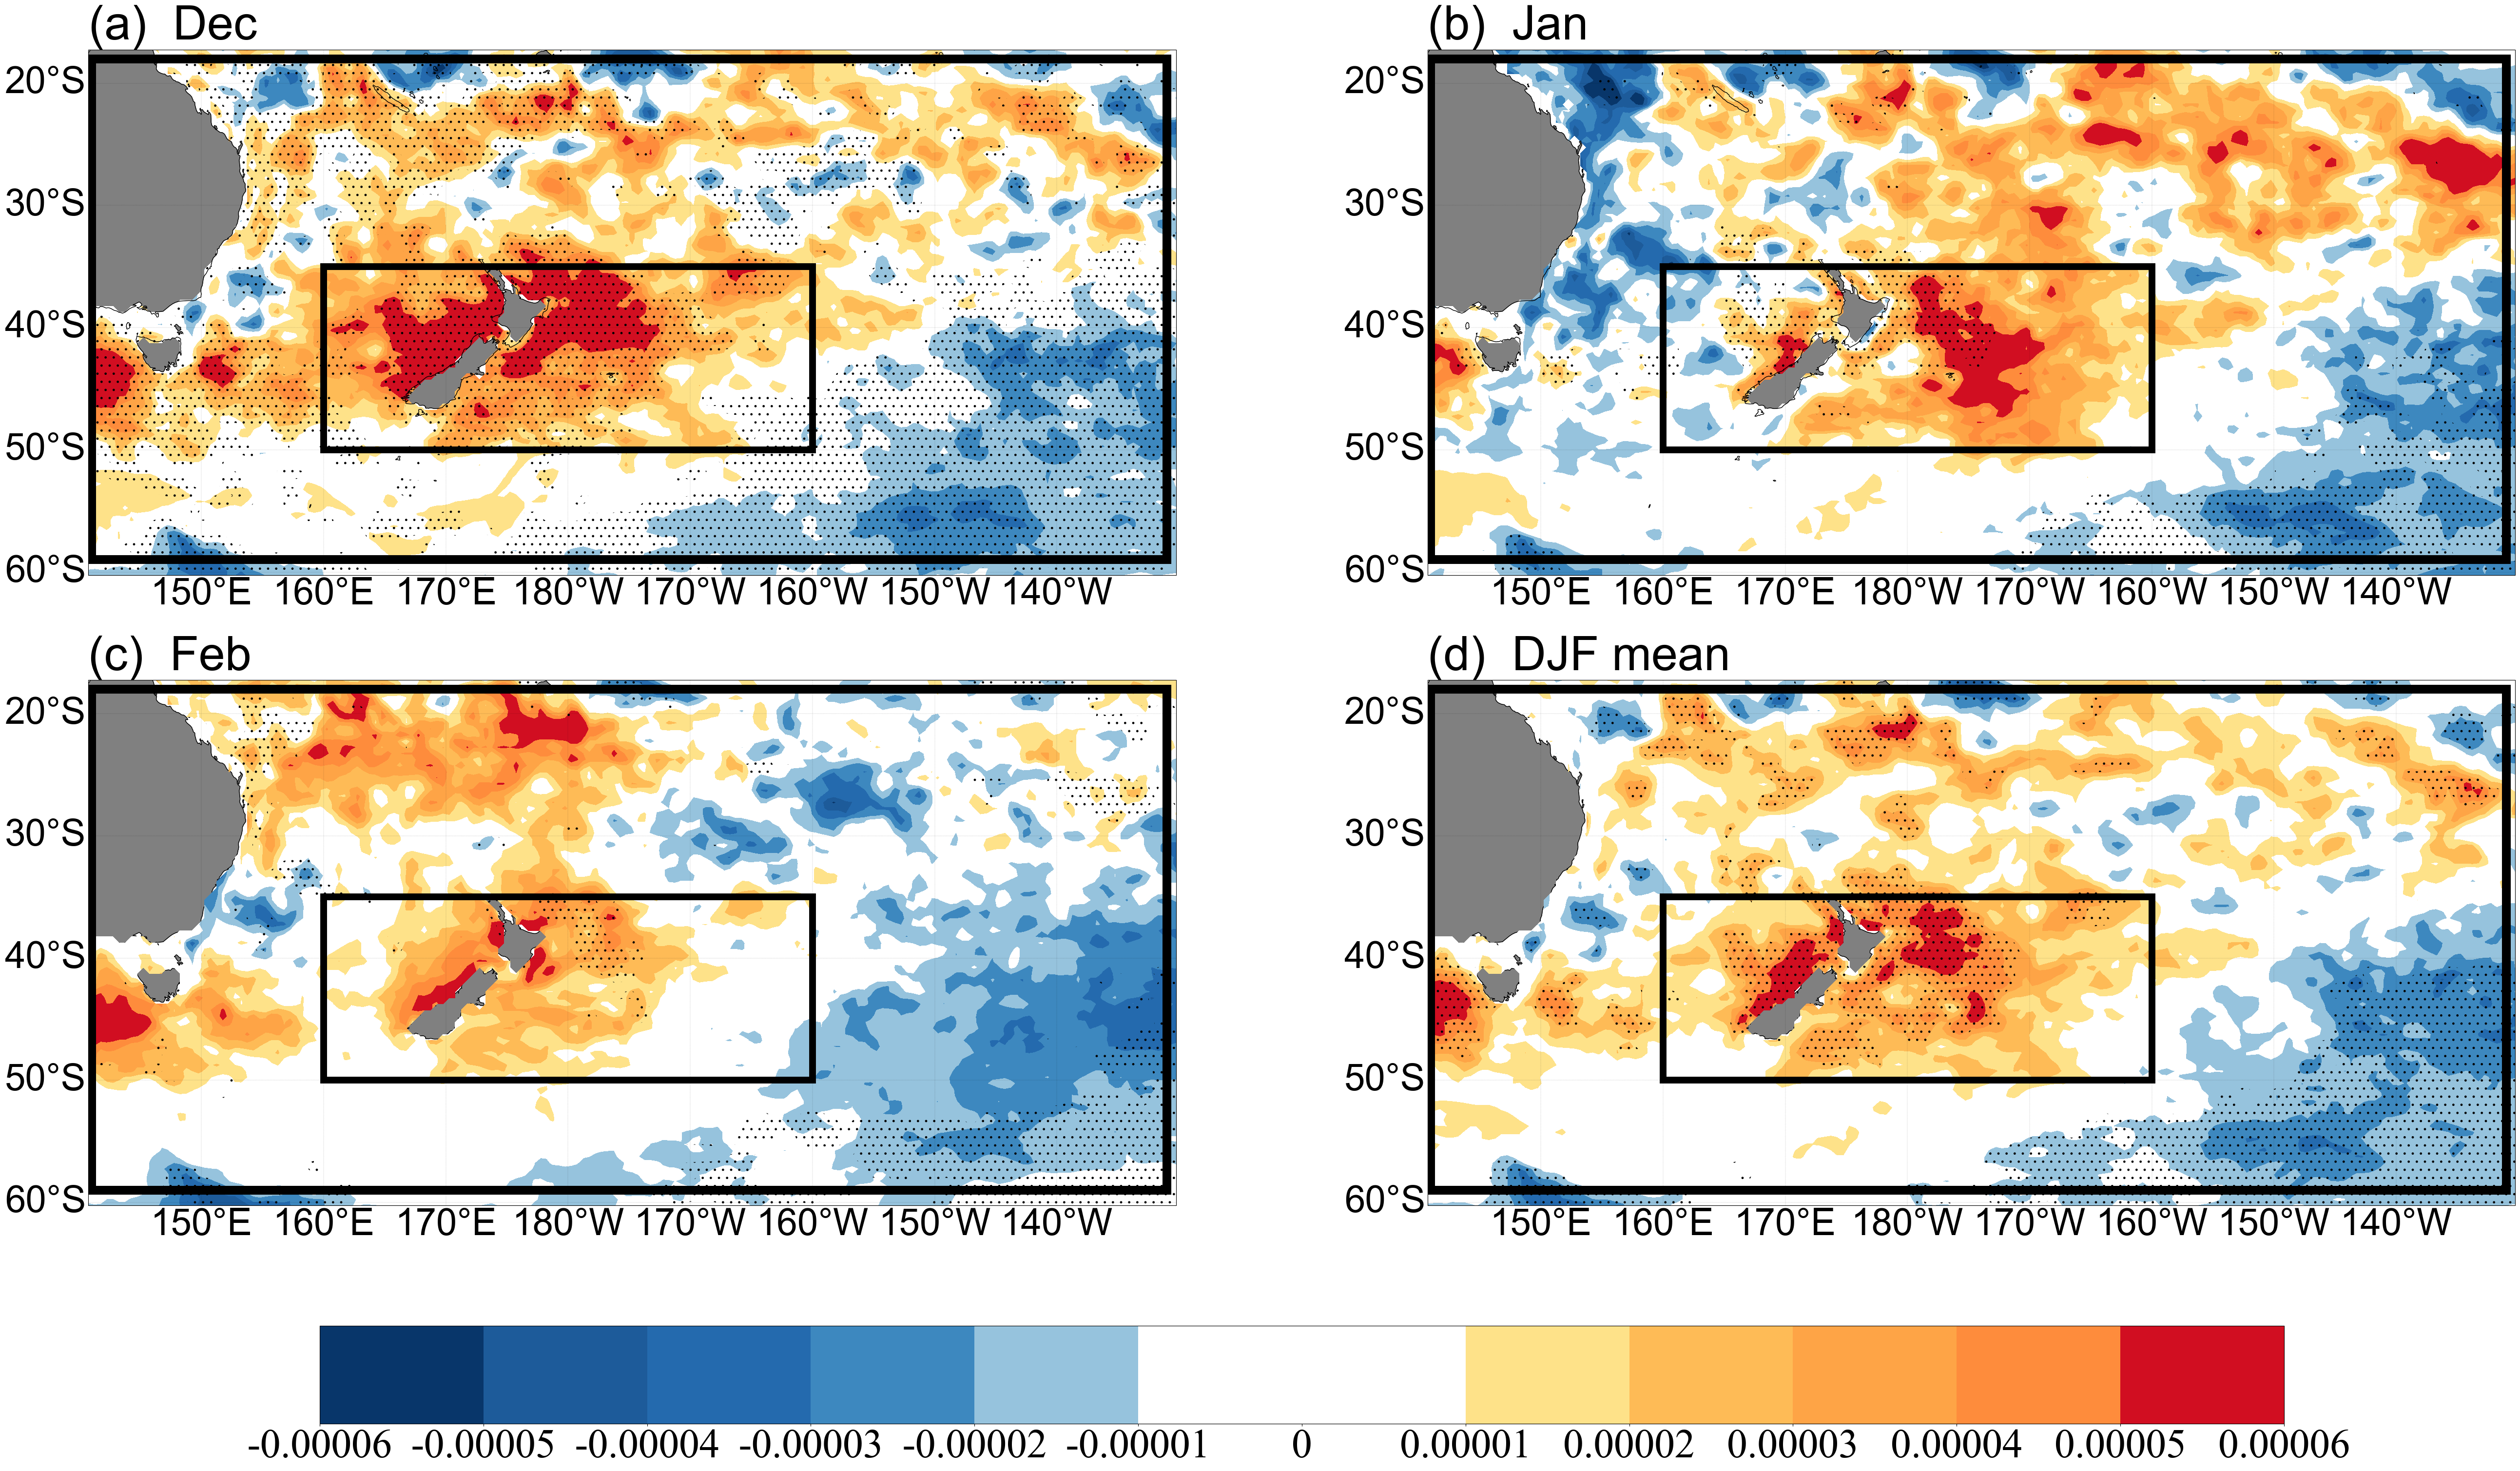

In [60]:
plt.figure(figsize=[100,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,40),subplot_kw={'projection': proj})
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,\
              edgecolor='blue',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
#ax[1][0].add_patch(RE)
#ax[1][1].add_patch(RE)
outline_point=(141,-59)
RE_4=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_5=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_6=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_7=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25




rectangles=[]

#colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
colors = ['#08366a','#246aae','#5fa5cd','#cae1ee','#ffffff','#ffffff','#ffffff','#ffffff','#fffac0', '#fee289','#febb56','#fe8c3c','#d10e21']
colors =['#08366a','#1D5B9A','#246aae','#3D88BF','#5fa5cd','#96C3DD','#cae1ee','#ffffff','#ffffff','#fffac0','#FDEEA4' ,'#fee289','#FEC562','#febb56','#FEA446','#fe8c3c','#E95A29','#d10e21']
colors =['#08366a','#1D5B9A','#246aae','#3D88BF','#5fa5cd','#96C3DD','#ffffff','#ffffff','#fee289','#FEC562','#febb56','#FEA446','#fe8c3c','#E95A29','#d10e21']
# 创建颜色映射
cmap = ListedColormap(colors)
# 设置颜色映射范围
vmin, vmax = -0.00006, 0.00006
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 12)
levels=[-0.00006,-0.00005,-0.00004,-0.00003,
       -0.00002, -0.00001, 0, 0.00001,
       0.00002, 0.00003,  0.00004, 0.00005,
        0.00006]
norm = BoundaryNorm(levels, cmap.N)

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap=cmap)
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        #ax[i][j].set_xticklabels(fontsize='large', fontname='Arial') #设置刻度的显示文本，rotation旋转角度，fontsize字体大小
     
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':55,'family':'Arial'}
        gl.ylabel_style = {'size':55,'family':'Arial'}
        rect = plt.Rectangle(start_point, 200-160, -35+50, linewidth=10, linestyle='-', zorder=5,
                             edgecolor='black', facecolor='none', transform=ccrs.PlateCarree())
        ax[i][j].add_patch(rect)
        rectangles.append(rect)

ax[0][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[0,:,:],cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0),zorder=0)
ax[0][1].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[1,:,:], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0),zorder=0)
c=ax[1][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[2,:,:],cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,a[0,1].mean(axis=0), cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))

ax[0][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[0,:,:],colors='#d10e21',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0),zorder=0)
ax[0][1].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[1,:,:], colors='#d10e21',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0),zorder=0)
ax[1][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[2,:,:],colors='#d10e21',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,a[0,1].mean(axis=0), colors='#d10e21',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[0,:,:],colors='#08366a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0),zorder=0)
ax[0][1].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[1,:,:], colors='#08366a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0),zorder=0)
ax[1][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[2,:,:],colors='#08366a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,a[0,1].mean(axis=0), colors='#08366a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))




#ax[0][0].contourf(Lon, Lat, N_square_anom_compose_monthly_mean[0,:,:], color='white', transform=ccrs.PlateCarree(0), vmin=vmin, vmax=vmax)
#ax[0][1].contourf(Lon, Lat, N_square_anom_compose_monthly_mean[1,:,:], cmap=cmap, transform=ccrs.PlateCarree(0), zorder=0, vmin=vmin, vmax=vmax,zorder=1)
#c = ax[1][0].contourf(Lon, Lat, N_square_anom_compose_monthly_mean[2,:,:], cmap=cmap, transform=ccrs.PlateCarree(0), vmin=vmin, vmax=vmax,zorder=1)
#ax[1][1].contourf(Lon, Lat, a[0,1].mean(axis=0), cmap=cmap, transform=ccrs.PlateCarree(0), vmin=vmin, vmax=vmax,zorder=1)

ax[0][0].add_patch(RE_4)
ax[0][1].add_patch(RE_5)
ax[1][0].add_patch(RE_6)
ax[1][1].add_patch(RE_7)

RE_4.set_linewidth(13)
RE_5.set_linewidth(13)
RE_6.set_linewidth(13)
RE_7.set_linewidth(13)

ax[0][0].set_title(r'(a) '+' '+'Dec',fontsize=70,fontname='Arial',loc='left')
ax[0][1].set_title(r'(b) '+' '+'Jan',fontsize=70,fontname='Arial',loc='left')
ax[1][0].set_title(r'(c) '+' '+'Feb',fontsize=70,fontname='Arial',loc='left')
ax[1][1].set_title(r'(d) '+' '+'DJF mean',fontsize=70,fontname='Arial',loc='left')
cb=plt.colorbar(c, ax=ax ,orientation='horizontal', shrink=0.8,pad=0.08,ticks=[-0.00006,-0.00005,-0.00004,-0.00003,
       -0.00002, -0.00001, 0, 0.00001,
       0.00002, 0.00003,  0.00004, 0.00005,
        0.00006])


clp=ax[0][0].contourf(Lon,Lat,p_N_square12,levels =[0,0.5],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_N_square1,levels =[0,0.1],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_N_square2,levels =[0,0.1],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_N_square_DJF,levels =[0,0.1],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_scientific(False)
cb.ax.yaxis.set_major_formatter(formatter)
cb.set_ticklabels(['-0.00006', '-0.00005','-0.00004','-0.00003','-0.00002', '-0.00001', '0','0.00001',
       '0.00002',  '0.00003', '0.00004', '0.00005','0.00006'])
font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=60)

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\geoaxes.py:1508: UserWarning: The following kwargs were not used by contour: 'color'
  result = matplotlib.axes.Axes.contourf(self, *args, **kwargs)


<Figure size 10000x8000 with 0 Axes>

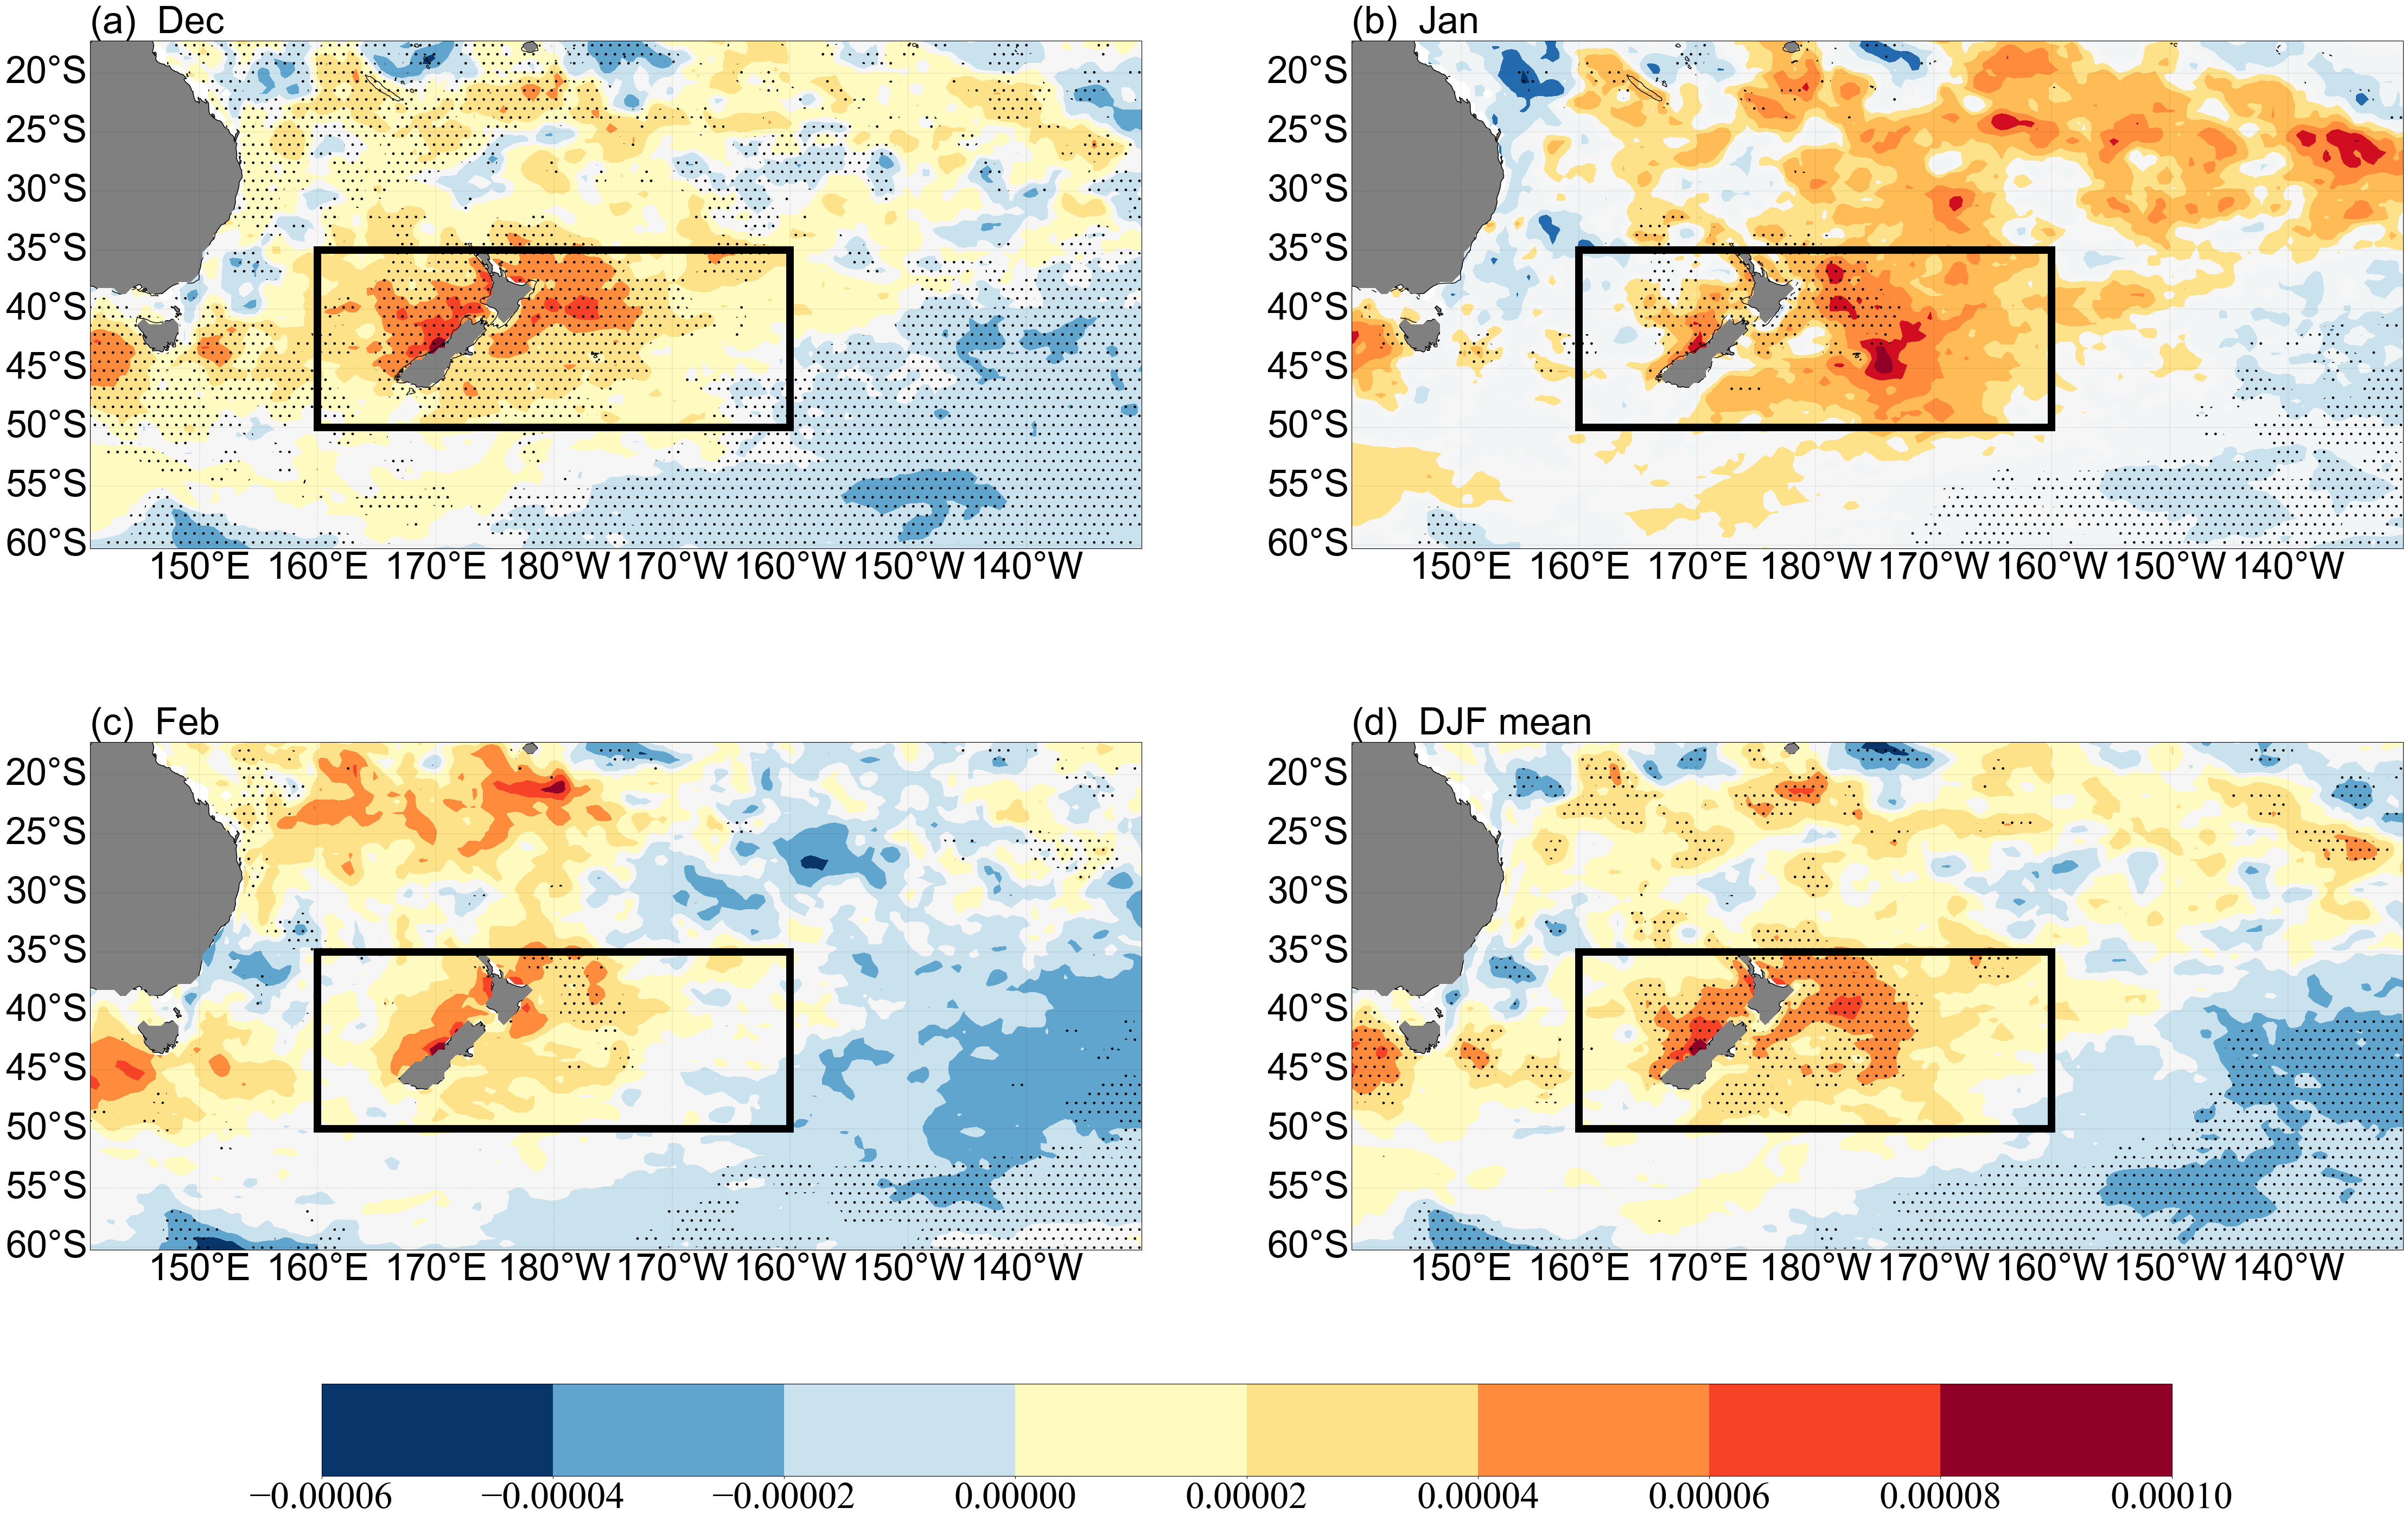

In [61]:
plt.figure(figsize=[100,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(55,40),subplot_kw={'projection': proj})
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,\
              edgecolor='blue',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
#ax[1][0].add_patch(RE)
#ax[1][1].add_patch(RE)
rectangles=[]

#colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
colors = ['#08366a','#246aae','#5fa5cd','#cae1ee','#f2f5f6','#fffac0', '#fee289','#febb56','#fe8c3c','#f64227','#d10e21','#910026']
#colors = ['#08366a','#1d5fa2','#246aae','#3f8ec0','#5fa5cd','#cae1ee','#f2f5f6','#fffac0', '#fee289','#febb56','#fe8c3c','#f64227','#d10e21','#910026']
#colors = ['#08366a','#175290','#1d5fa2','#246aae','#3f8ec0','#5fa5cd','#f2f5f6','#fffac0', '#fee289','#febb56','#fe8c3c','#f64227','#d10e21','#910026']

# 创建颜色映射
cmap = ListedColormap(colors)


for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap=cmap)
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        #ax[i][j].set_xticklabels(fontsize='large', fontname='Arial') #设置刻度的显示文本，rotation旋转角度，fontsize字体大小
     
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':50,'family':'Arial'}
        gl.ylabel_style = {'size':50,'family':'Arial'}
        rect = plt.Rectangle(start_point, 200-160, -35+50, linewidth=10, linestyle='-', zorder=5,
                             edgecolor='black', facecolor='none', transform=ccrs.PlateCarree())
        ax[i][j].add_patch(rect)
        rectangles.append(rect)

ax[0][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[0,:,:], cmap=cmap,transform=ccrs.PlateCarree(0),zorder=0)
ax[0][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[0,:,:],[-0.000005,0.000005], color='white',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[1,:,:], cmap=cmap,transform=ccrs.PlateCarree(0),zorder=0)
ax[0][1].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[1,:,:],[-0.000005,0.000005], color='white',transform=ccrs.PlateCarree(0))
c=ax[1][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[2,:,:],cmap=cmap,transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,N_square_anom_compose_monthly_mean[2,:,:],[-0.000005,0.000005], color='white',transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,a[0,1].mean(axis=0), cmap=cmap,transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,a[0,1].mean(axis=0),[-0.000005,0.000005], color='white',transform=ccrs.PlateCarree(0))



#ax[0][0].contourf(Lon, Lat, N_square_anom_compose_monthly_mean[0,:,:], color='white', transform=ccrs.PlateCarree(0), vmin=vmin, vmax=vmax)
#ax[0][1].contourf(Lon, Lat, N_square_anom_compose_monthly_mean[1,:,:], cmap=cmap, transform=ccrs.PlateCarree(0), zorder=0, vmin=vmin, vmax=vmax,zorder=1)
#c = ax[1][0].contourf(Lon, Lat, N_square_anom_compose_monthly_mean[2,:,:], cmap=cmap, transform=ccrs.PlateCarree(0), vmin=vmin, vmax=vmax,zorder=1)
#ax[1][1].contourf(Lon, Lat, a[0,1].mean(axis=0), cmap=cmap, transform=ccrs.PlateCarree(0), vmin=vmin, vmax=vmax,zorder=1)


ax[0][0].set_title(r'(a) '+' '+'Dec',fontsize=50,fontname='Arial',loc='left')
ax[0][1].set_title(r'(b) '+' '+'Jan',fontsize=50,fontname='Arial',loc='left')
ax[1][0].set_title(r'(c) '+' '+'Feb',fontsize=50,fontname='Arial',loc='left')
ax[1][1].set_title(r'(d) '+' '+'DJF mean',fontsize=50,fontname='Arial',loc='left')
cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type: ignore
                      orientation='horizontal', shrink=0.8,pad=0.08)


clp=ax[0][0].contourf(Lon,Lat,p_N_square12,levels =[0,0.5],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_N_square1,levels =[0,0.1],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_N_square2,levels =[0,0.1],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_N_square_DJF,levels =[0,0.1],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=50)

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


<Figure size 10000x8000 with 0 Axes>

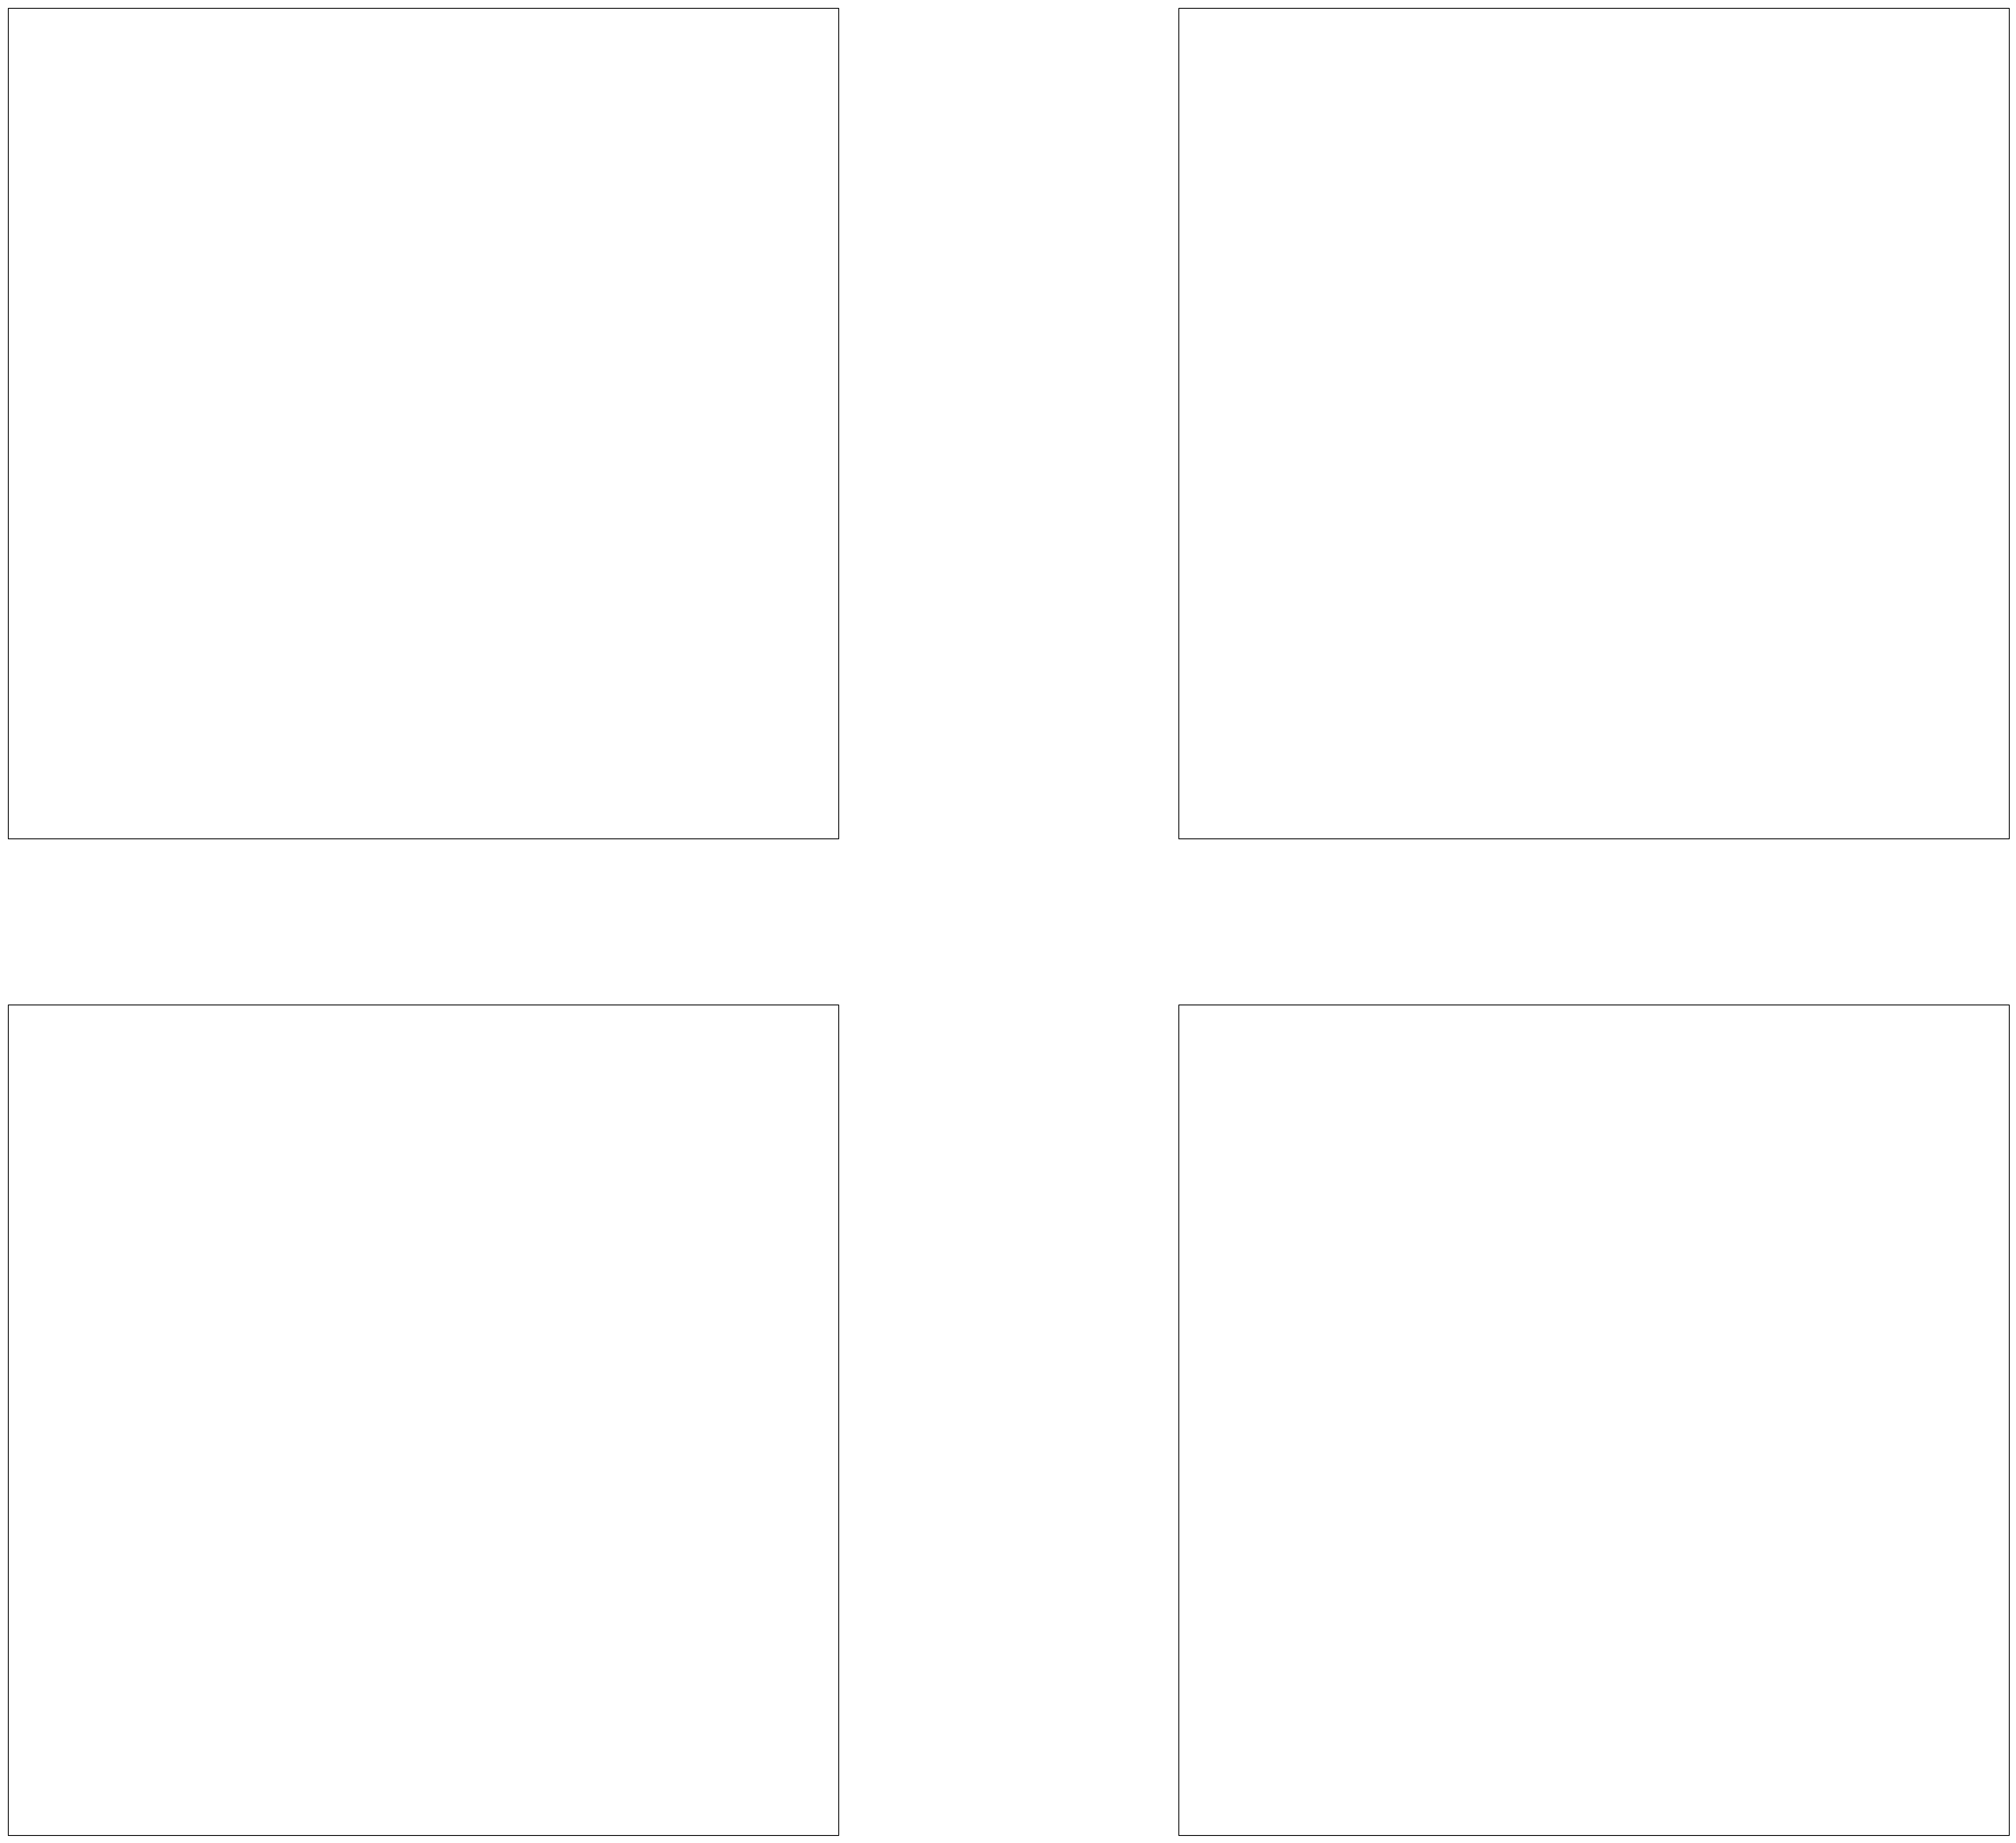

In [62]:
plt.figure(figsize=[100,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(35,30),subplot_kw={'projection': proj})
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='blue',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
#ax[1][0].add_patch(RE)
#ax[1][1].add_patch(RE)
rectangles=[]

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Reds')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        #ax[i][j].set_xticklabels(fontsize='large', fontname='Arial') #设置刻度的显示文本，rotation旋转角度，fontsize字体大小
     
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,180,5),np.arange(-180,-130,5)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':40,'family':'Arial'}
        gl.ylabel_style = {'size':40,'family':'Arial'}
        rect = plt.Rectangle(start_point, 200-160, -35+50, linewidth=10, linestyle='-', zorder=5,
                             edgecolor='black', facecolor='none', transform=ccrs.PlateCarree())
        ax[i][j].add_patch(rect)
        rectangles.append(rect)



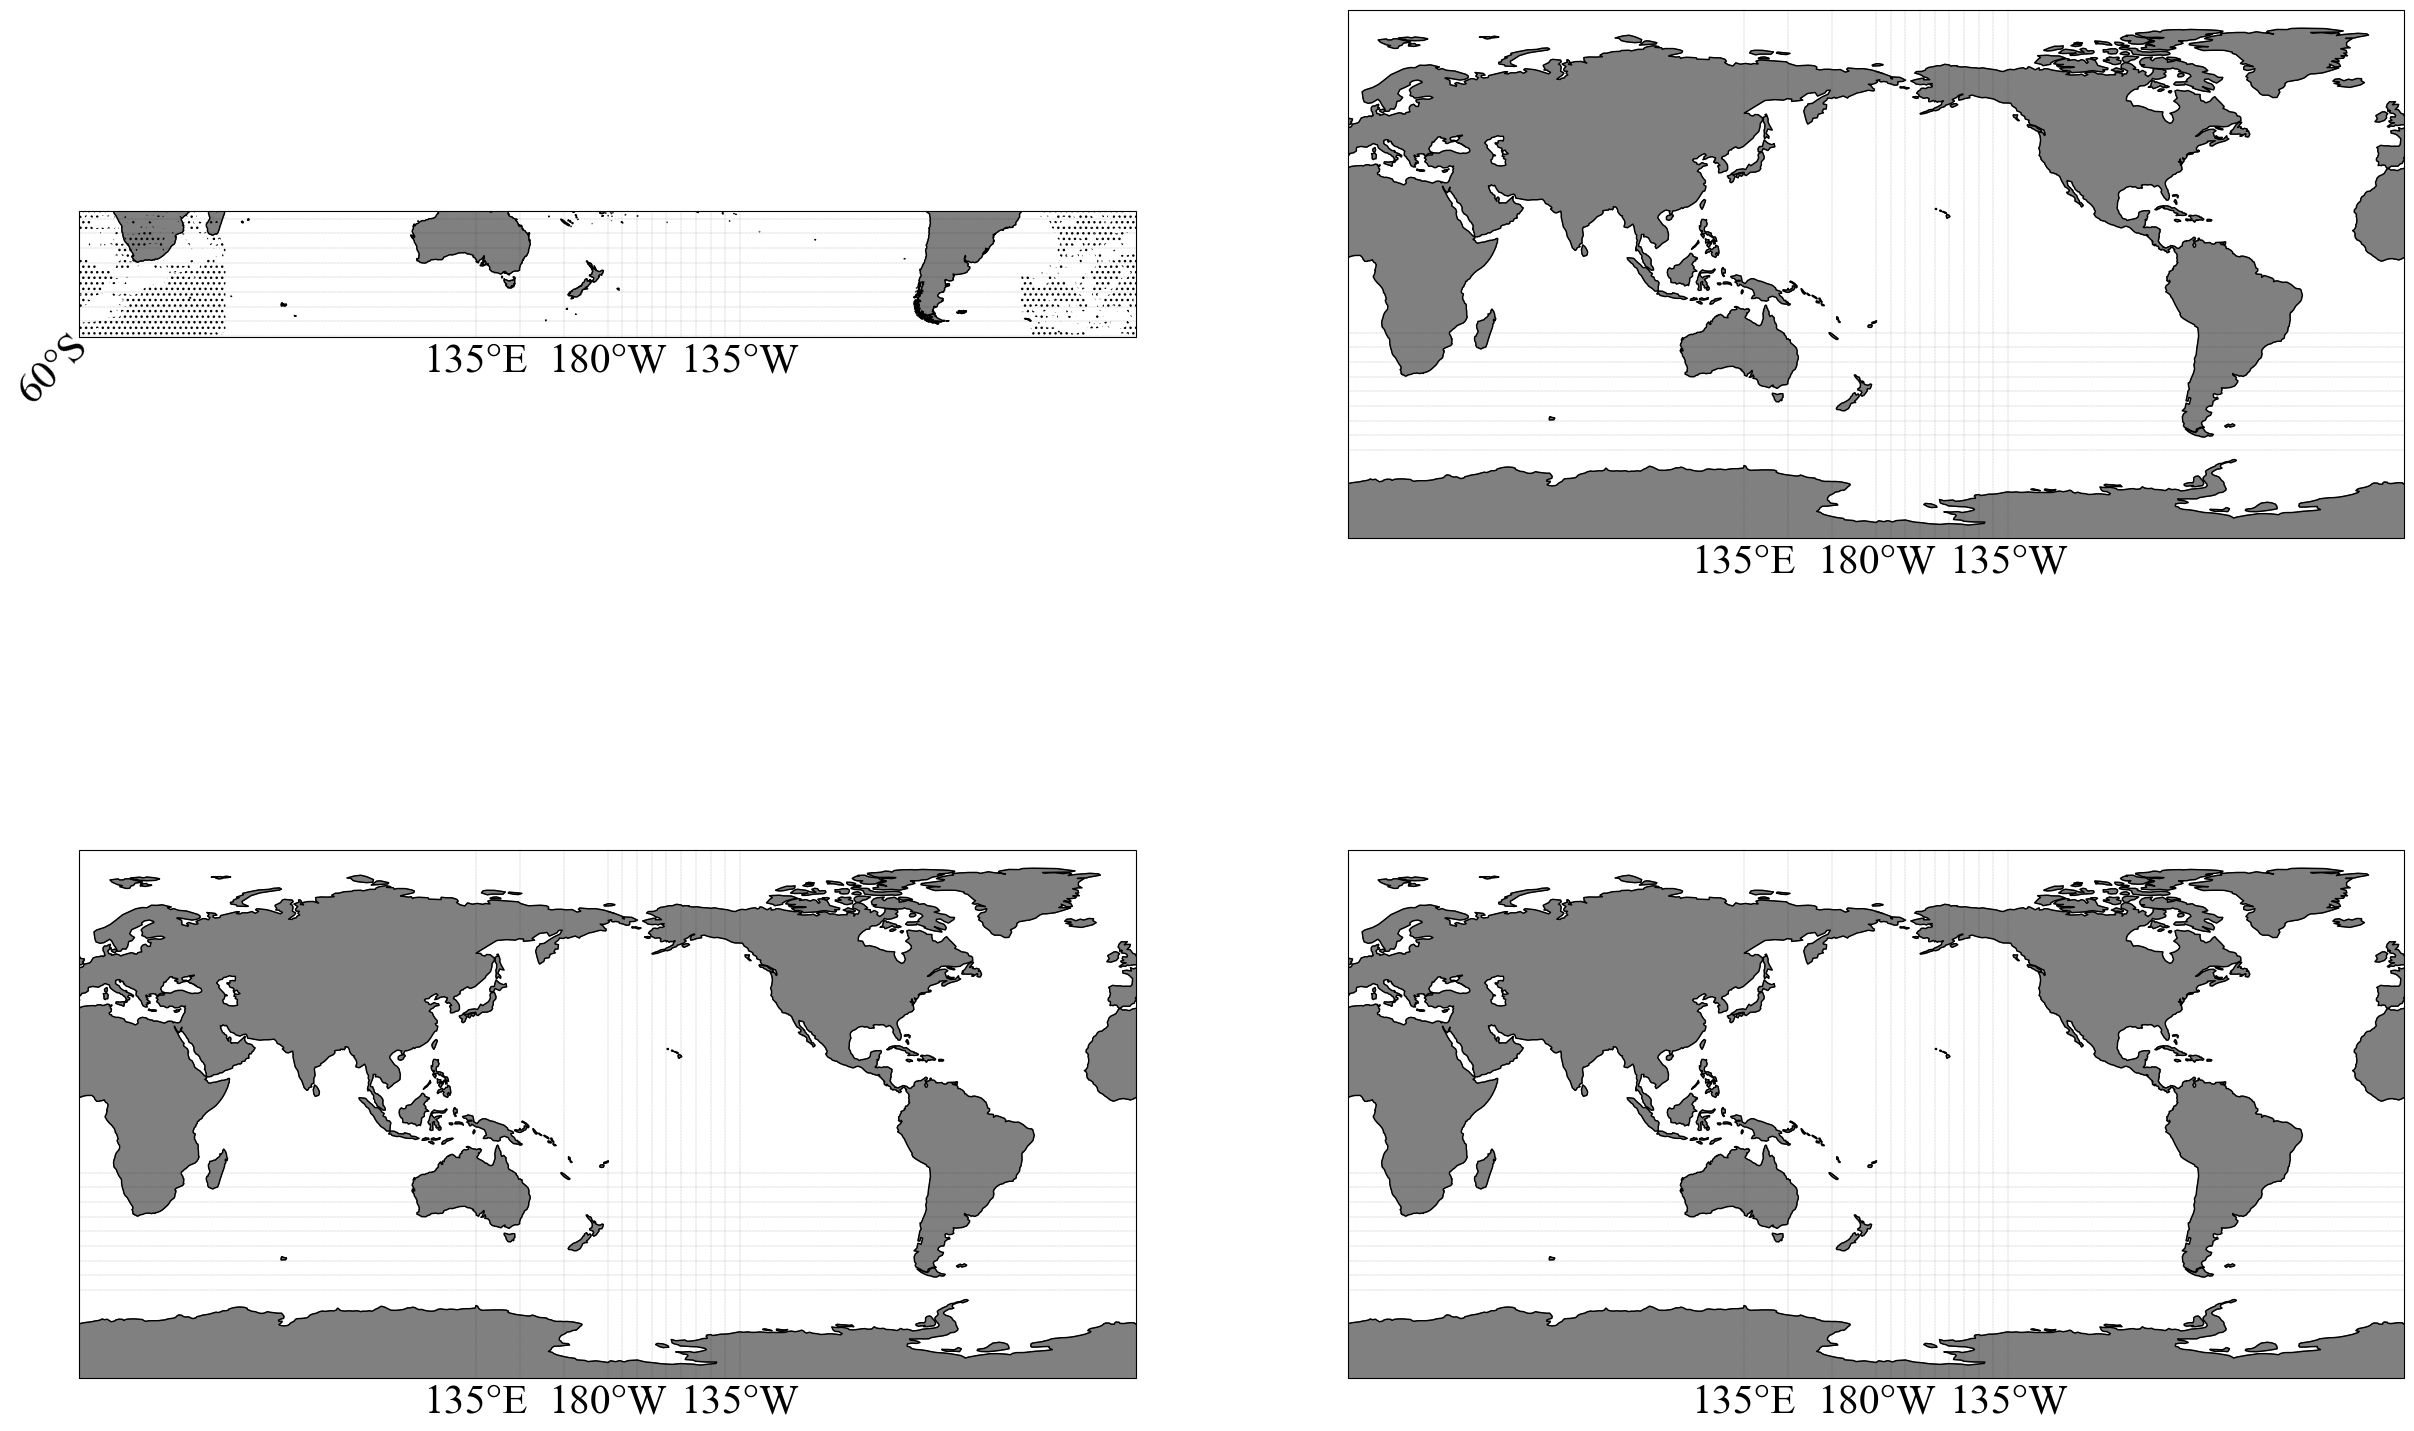

In [63]:
#plt.figure(figsize=[20,5])
from matplotlib.colors import ListedColormap#调色用的
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(30,20),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25



for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 30, "color": 'k'}     
        gl.ylabel_style = {'size': 30, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,15),np.arange(-180,-130,5)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER

# 创建粉红色系的颜色列表
#colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
# 创建颜色映射
cmap = ListedColormap(colors)

ax[0][0].contourf(Lon,Lat,p_N_square12,levels =[0,0.5],hatches=['...'],color='none',transform=ccrs.PlateCarree(180),alpha=0)

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_24660\1826194214.py:45: UserWarning: The following kwargs were not used by contour: 'color'
  ax2[0][0].contourf(Lon,Lat,p_N_square12,levels =[0,0.5],hatches=['...'],color='none',alpha=0)


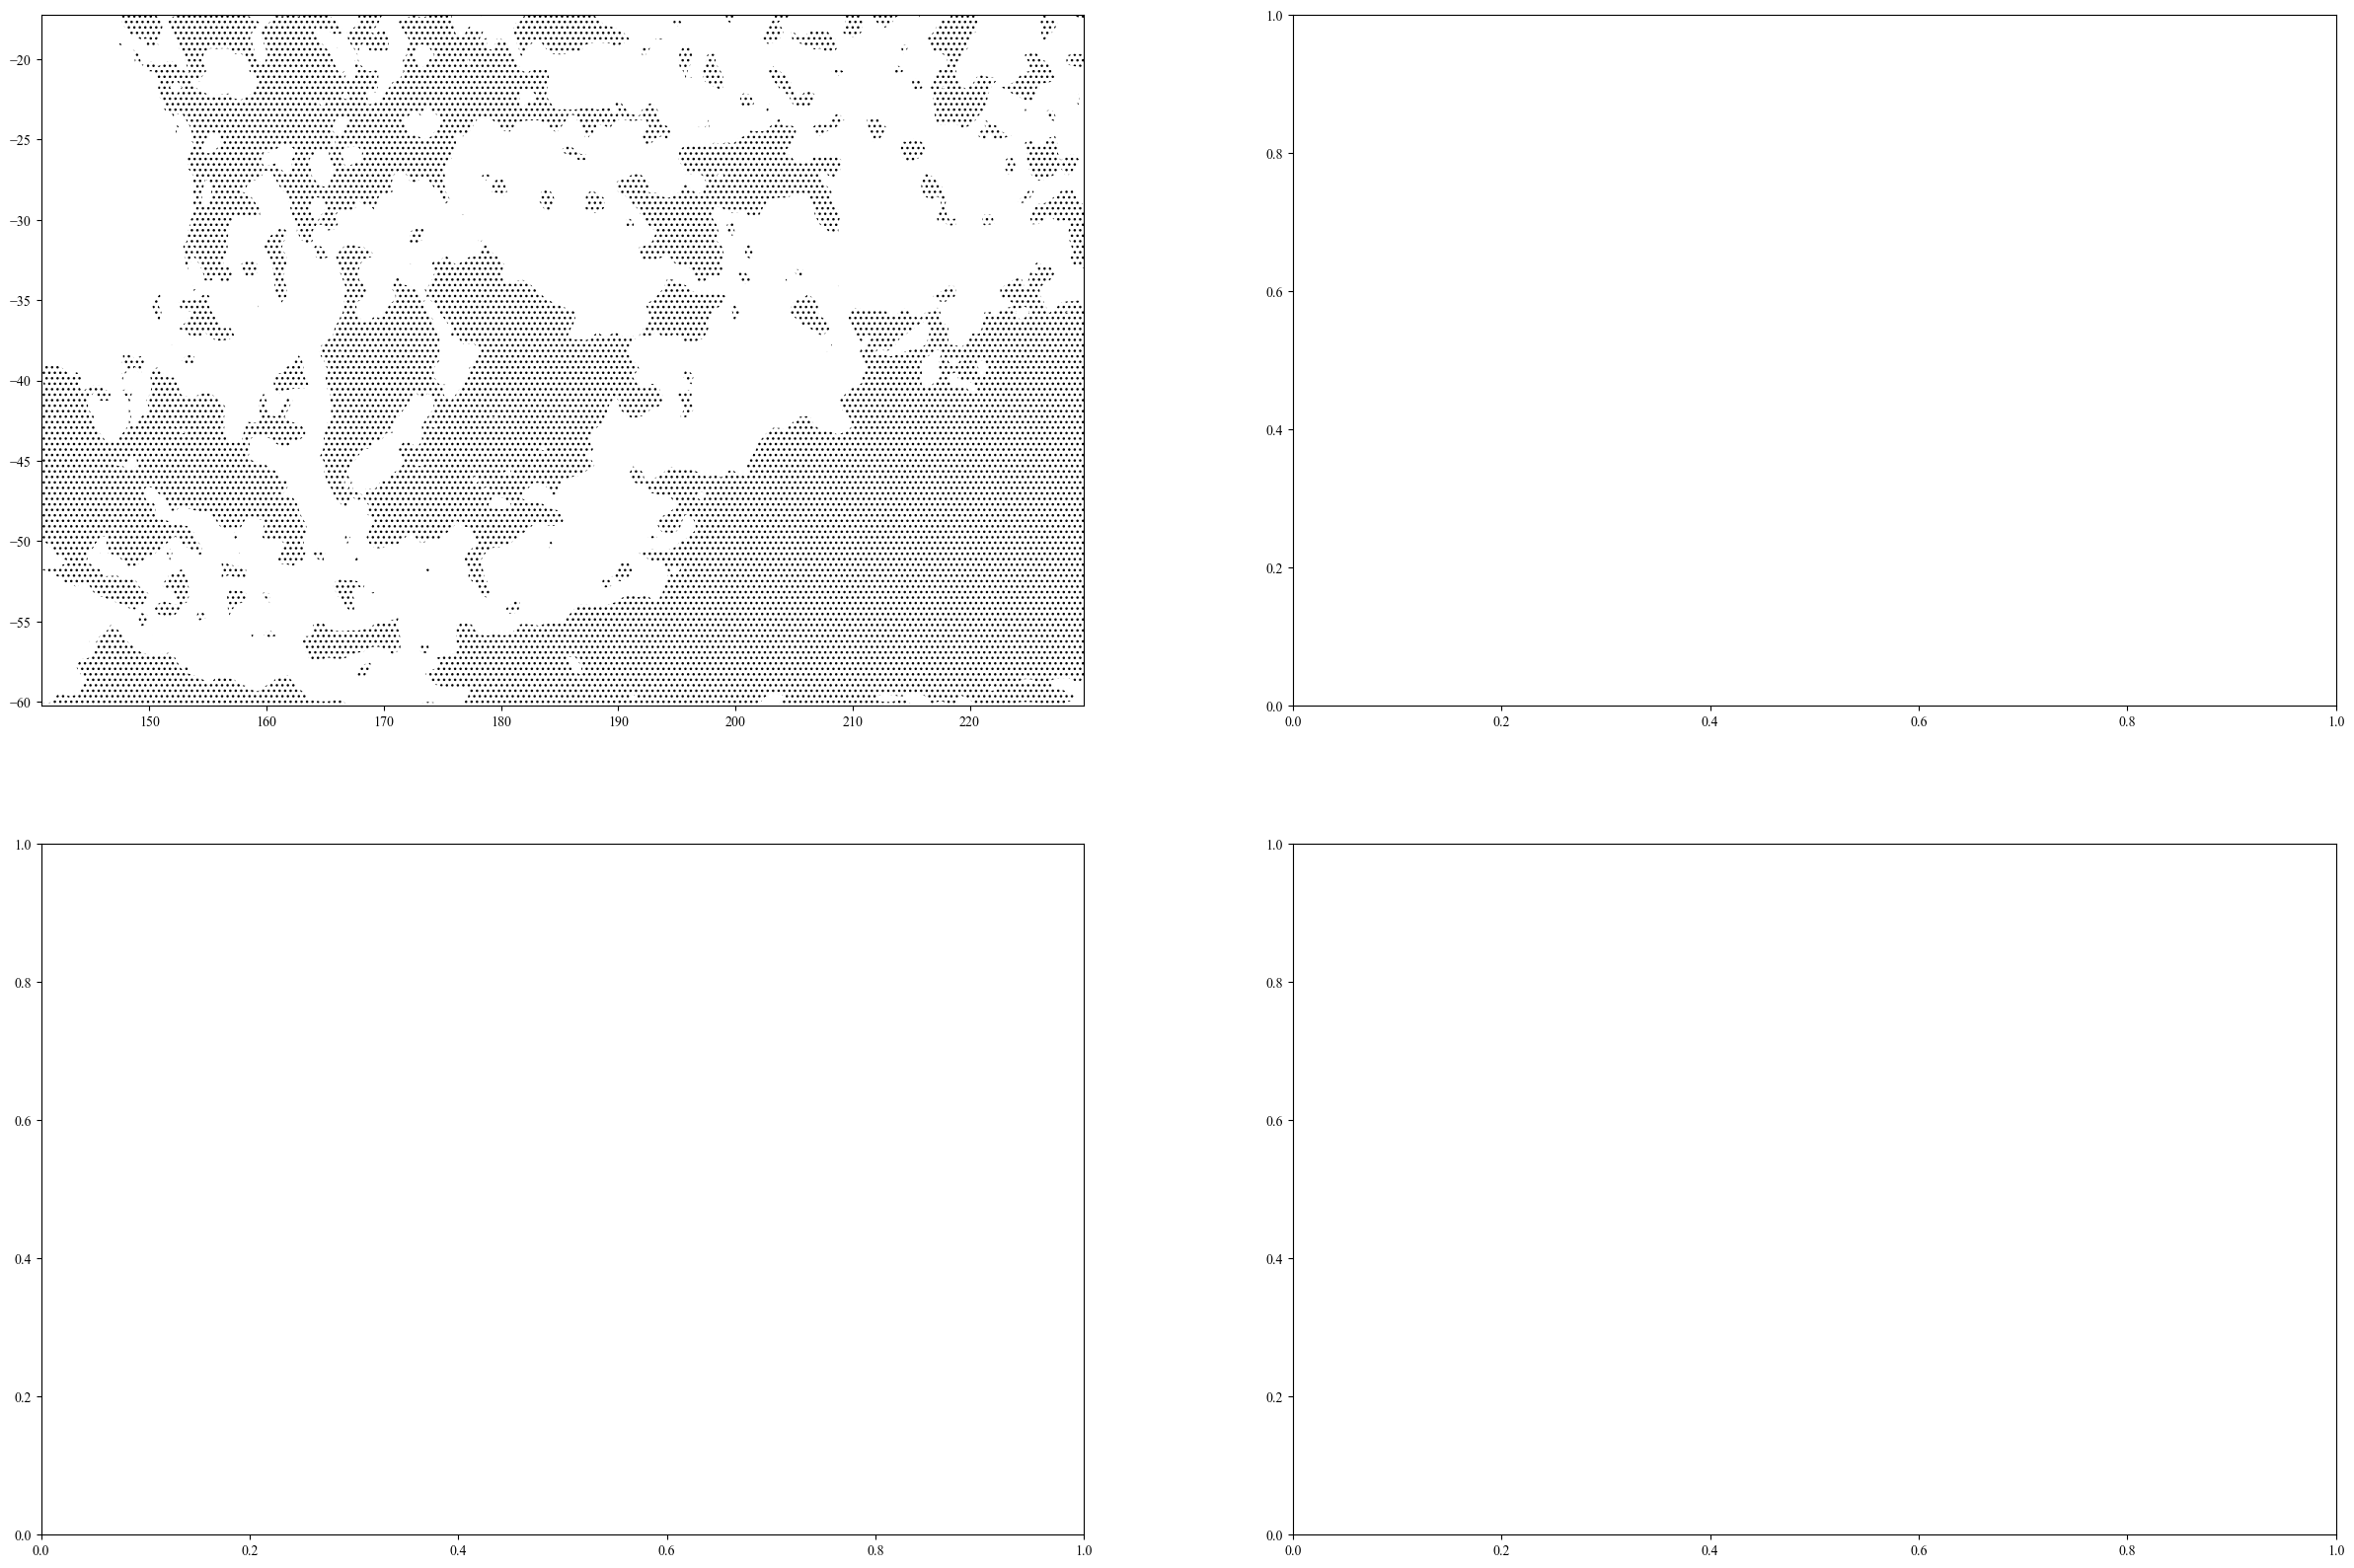

In [64]:
#plt.figure(figsize=[20,5])
#from matplotlib.colors import ListedColormap#调色用的
proj = ccrs.PlateCarree(central_longitude=180)
fig2,ax2=plt.subplots(2,2,figsize=(30,20))

# #添加框线
# start_point = (160, -50)
# RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
#               edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
# RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
#               edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
# RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
#               edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
# RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
#               edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25



# for i in range(0,2,1):
#     for j in range(0,2,1):
#         #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
#         gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
#         gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
#         gl.ylabels_right = False ##关闭右侧坐标显示
#         gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
#         gl.yformatter = LATITUDE_FORMATTER
#         ax[i][j].coastlines()##绘制默认海岸线
#         ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
#         ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
#         #ax[i][j].set_xticks(np.arange(-20,21,10))
#         gl.xlabel_style = {'size': 30, "color": 'k'}     
#         gl.ylabel_style = {'size': 30, "color": 'k'}
#         gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,15),np.arange(-180,-130,5)]))
#         gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
#         gl.xformatter = LONGITUDE_FORMATTER
#         gl.yformatter = LATITUDE_FORMATTER

# # 创建粉红色系的颜色列表
# #colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
# colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
# # 创建颜色映射
# cmap = ListedColormap(colors)

ax2[0][0].contourf(Lon,Lat,p_N_square12,levels =[0,0.5],hatches=['...'],color='none',alpha=0)


In [65]:
ax2[0][0]

<AxesSubplot:>

<Figure size 10000x8000 with 0 Axes>

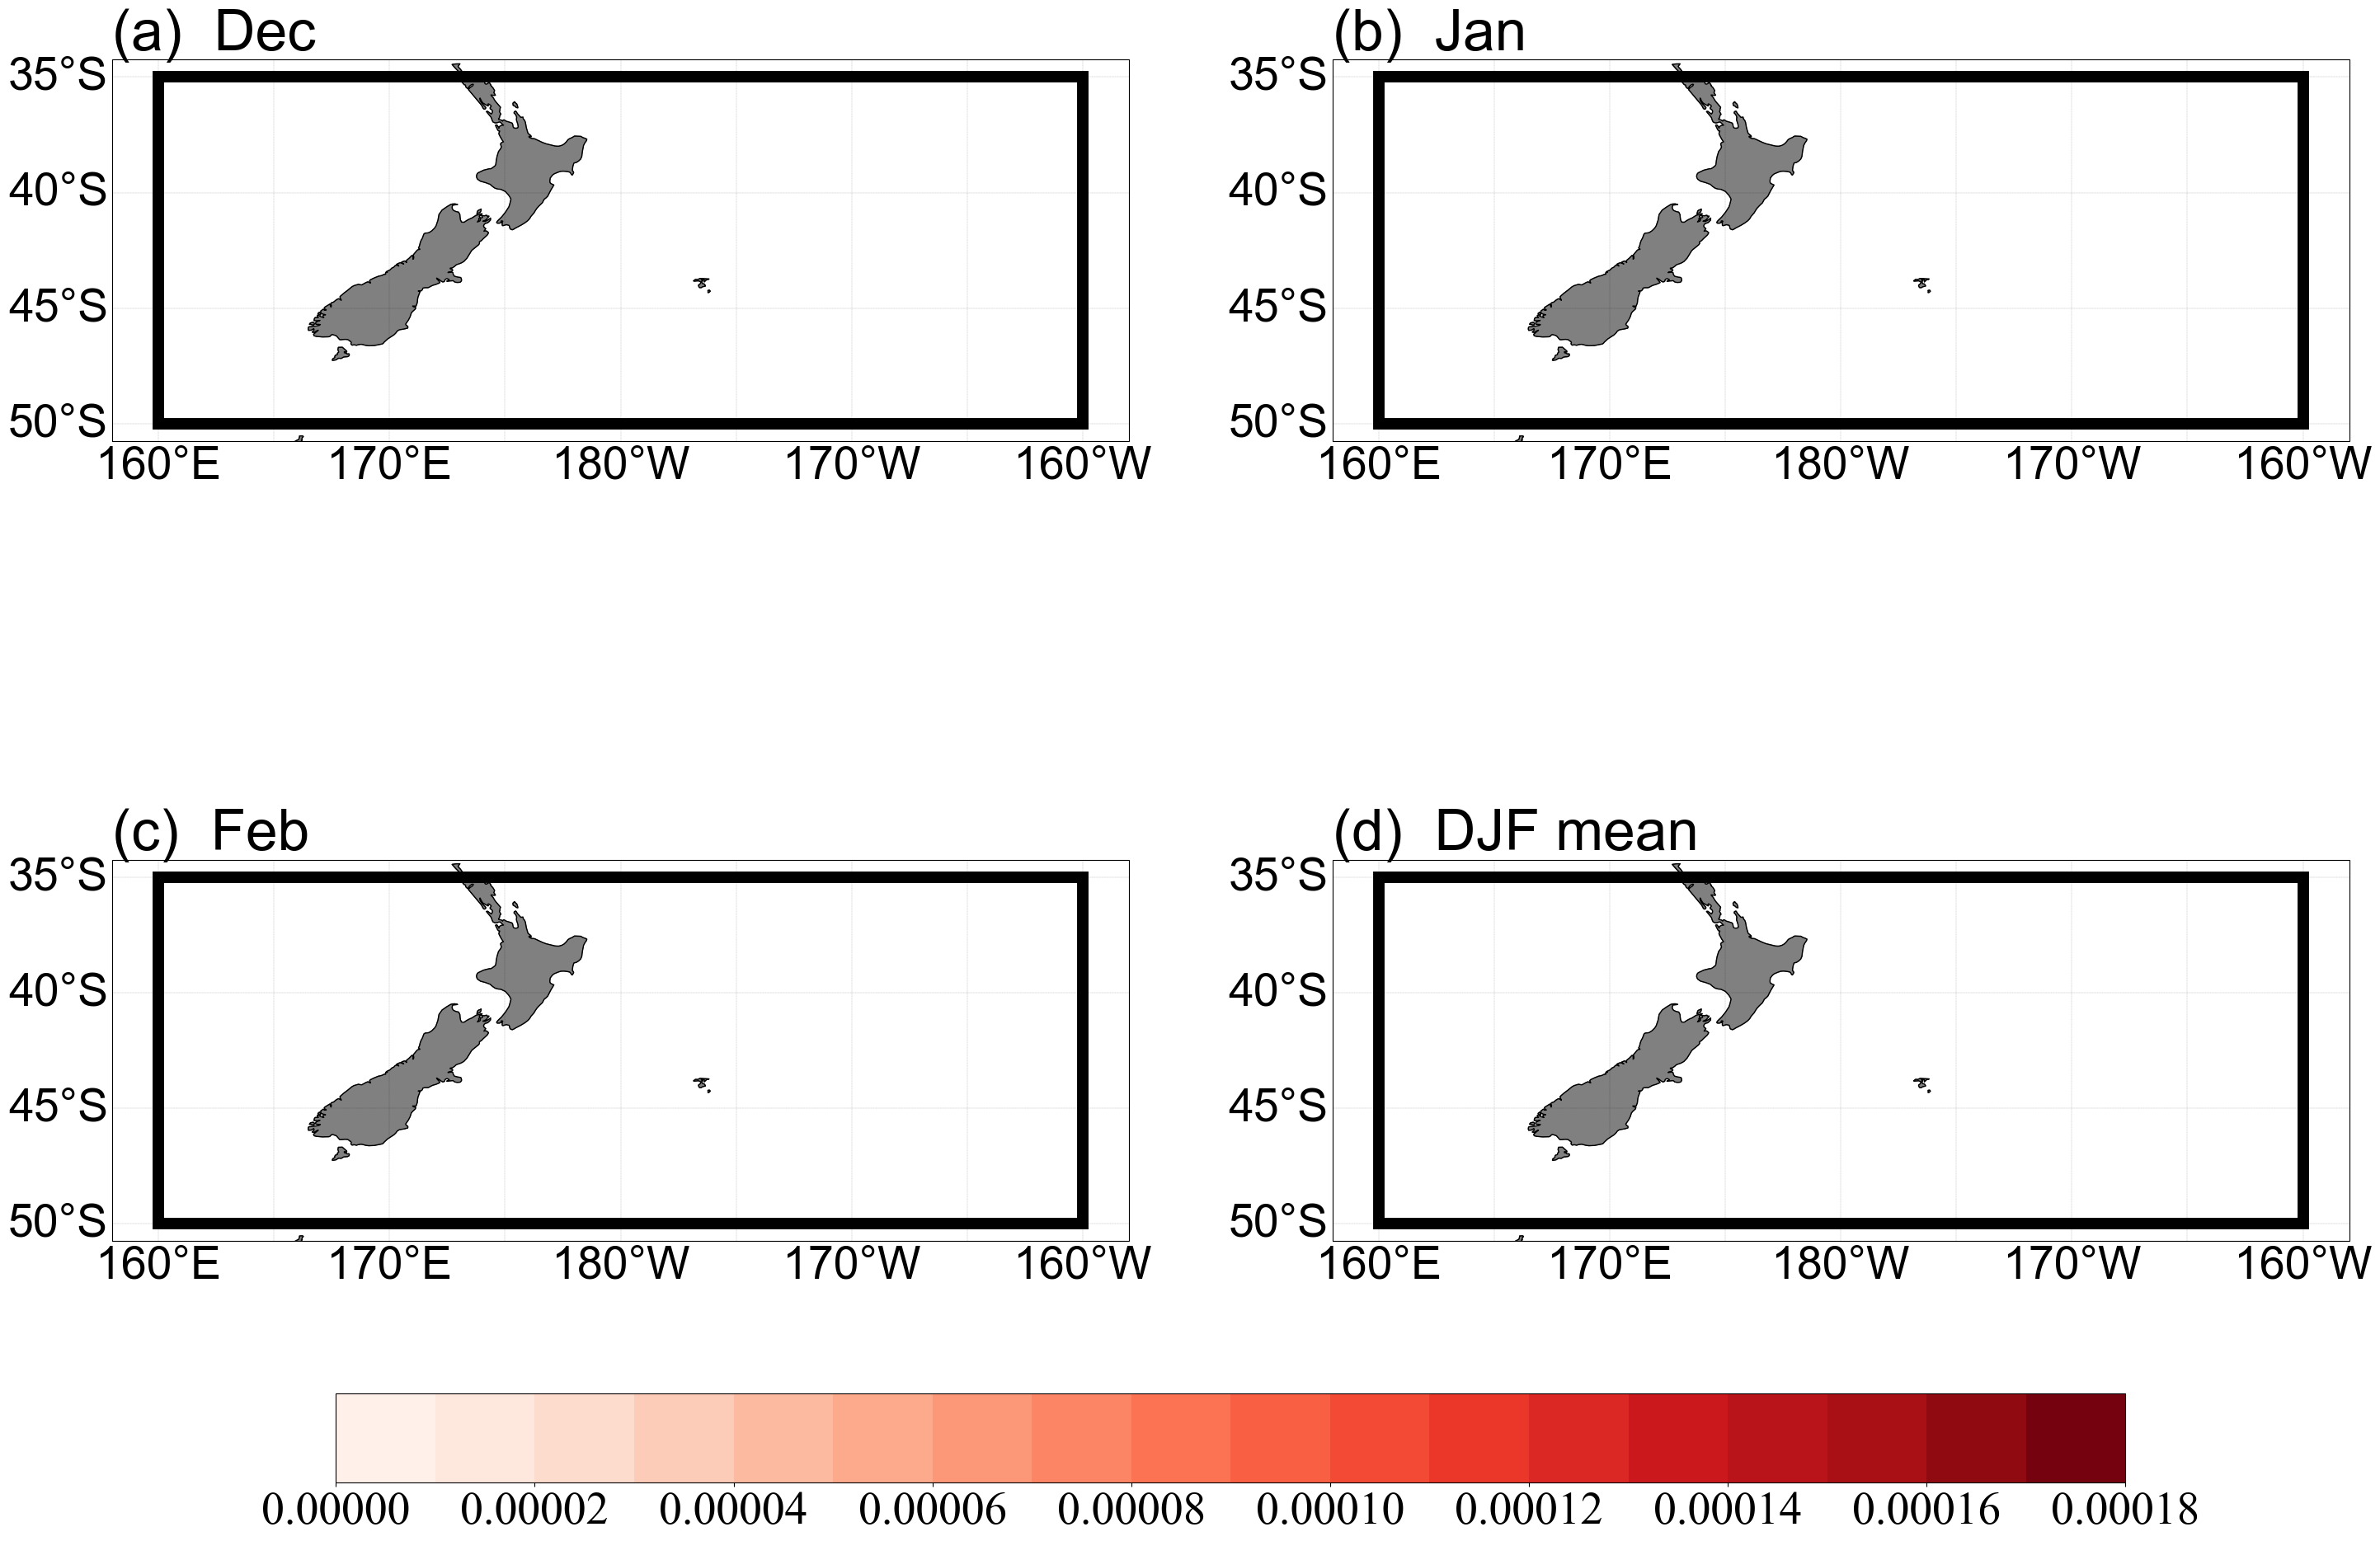

In [66]:
plt.figure(figsize=[100,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(35,30),subplot_kw={'projection': proj})
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='blue',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
#ax[1][0].add_patch(RE)
#ax[1][1].add_patch(RE)
rectangles=[]

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Reds')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        #ax[i][j].set_xticklabels(fontsize='large', fontname='Arial') #设置刻度的显示文本，rotation旋转角度，fontsize字体大小
     
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,180,5),np.arange(-180,-130,5)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':40,'family':'Arial'}
        gl.ylabel_style = {'size':40,'family':'Arial'}
        rect = plt.Rectangle(start_point, 200-160, -35+50, linewidth=10, linestyle='-', zorder=5,
                             edgecolor='black', facecolor='none', transform=ccrs.PlateCarree())
        ax[i][j].add_patch(rect)
        rectangles.append(rect)

ax[0][0].contourf(Lat,Lon,N_square_monthly[11,:,:],np.arange(0,0.00019,0.00001), cmap='Reds',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lat,Lon,N_square_monthly[0,:,:],np.arange(0,0.00019,0.00001), cmap='Reds',transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lat,Lon,N_square_monthly[2,:,:], np.arange(0,0.00019,0.00001),cmap='Reds',transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lat,Lon,N_square_seasonaly[0,:,:],np.arange(0,0.00019,0.00001), cmap='Reds',transform=ccrs.PlateCarree(0))
ax[0][0].set_title(r'(a) '+' '+'Dec',fontsize=50,fontname='Arial',loc='left')
ax[0][1].set_title(r'(b) '+' '+'Jan',fontsize=50,fontname='Arial',loc='left')
ax[1][0].set_title(r'(c) '+' '+'Feb',fontsize=50,fontname='Arial',loc='left')
ax[1][1].set_title(r'(d) '+' '+'DJF mean',fontsize=50,fontname='Arial',loc='left')
cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type: ignore
                      orientation='horizontal', shrink=0.8,pad=0.08)

font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=40)

In [67]:
np.arange(0,0.00019,0.00001)
np.arange(0,0.00019,0.00001)
np.arange(0,0.00019,0.00001)
np.arange(0,0.00019,0.00001)

array([0.0e+00, 1.0e-05, 2.0e-05, 3.0e-05, 4.0e-05, 5.0e-05, 6.0e-05,
       7.0e-05, 8.0e-05, 9.0e-05, 1.0e-04, 1.1e-04, 1.2e-04, 1.3e-04,
       1.4e-04, 1.5e-04, 1.6e-04, 1.7e-04, 1.8e-04])

NameError: name 'N_square_anom_monthly_mean' is not defined

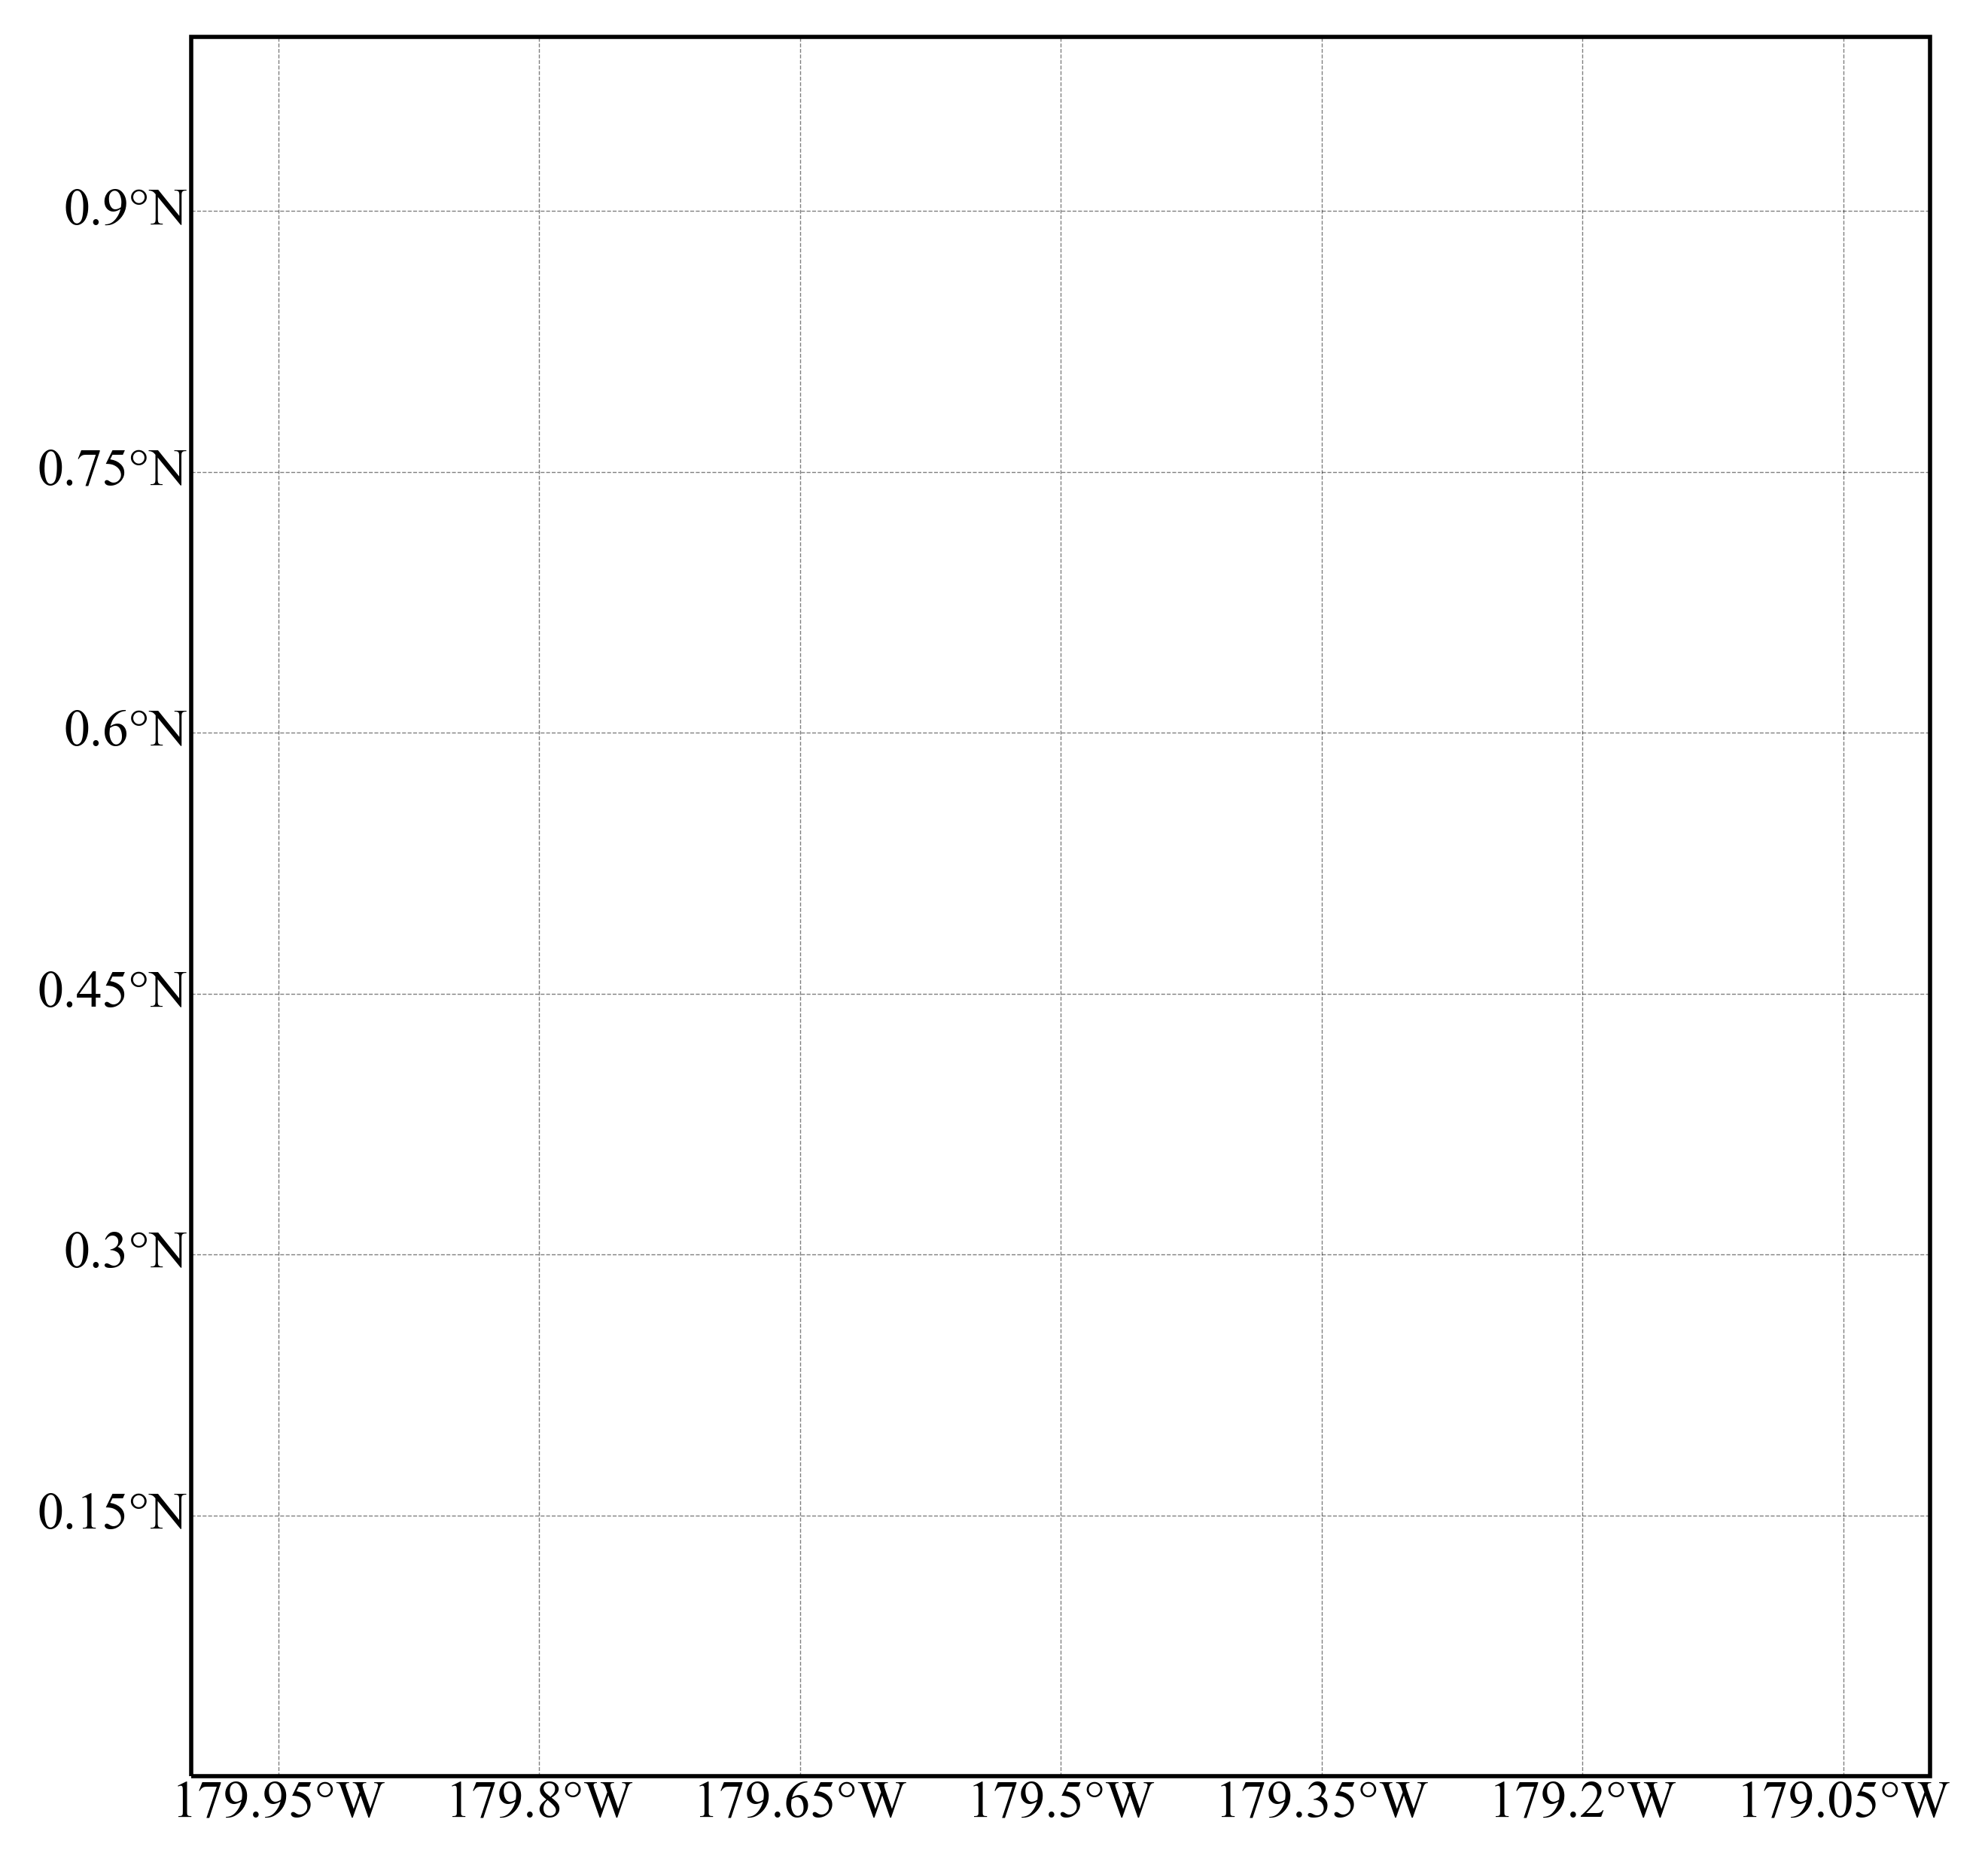

In [68]:
fig = plt.figure(figsize=(6, 6), dpi=500)  # 创建画布
proj = ccrs.PlateCarree(180)

ax = fig.subplots(1, 1, subplot_kw={'projection': proj})  # 创建子图

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
gl.xlabels_top = False ##关闭上侧坐标显示
gl.ylabels_right = False ##关闭右侧坐标显示
gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
gl.yformatter = LATITUDE_FORMATTER
#gl.xlocator = mticker.FixedLocator(np.arange(extent[0], extent[1], 15))
#gl.ylocator = mticker.FixedLocator(np.arange(extent[2], extent[3], 10))

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='blue',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
ax.add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
#Colors=('#CD5C5C')
c=ax.contourf(Lat,Lon,N_square_anom_monthly_mean[11,:,:],cmap='viridis',transform=ccrs.PlateCarree(0))
#ax.set_title("mld_Feb")
plt.legend()
#plt.clabel(d, inline=True, fontsize=8)
ax.coastlines()##绘制默认海岸线
ax.add_feature(cfeature.LAND,color='grey')####添加陆地######
ax.add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
cbar=plt.colorbar(c,orientation="horizontal")